# Laboratorio 9: Series de tiempo y forecasting 
##  Deep Learning y Sistemas Inteligentes

Melisa Dayana Mendizabal Melendez 23778
Renato Manuel Rojas Roldán 23813

El código reutilizable se escribe en el paquete `lab9/` con `%%writefile`, para que se pueda leer aquí 

### Archivos que exporta

| Archivo | Contenido |
|---|---|
| `data/hourly.parquet` | Panel horario limpio en formato largo `unique_id, ds, y` (kWh) |
| `data/clients.csv`, `data/series_stats.csv`, `data/holidays_pt.csv` | Clientes del panel, estadísticos de entrenamiento y feriados |
| `preds/<modelo>.parquet` | Pronósticos de prueba de cada modelo: `unique_id, ds, cutoff, h, y, y_hat, model` |
| `preds/test_predictions_parte1.parquet` | Todos los pronósticos de prueba juntos: `unique_id, ds, modelo, y_hat` |
| `results/runs.csv`, `results/history/*.csv` | Registro de cada entrenamiento (configuración, pérdidas por epoch, tiempos, memoria) |
| `results/test_metrics_parte1.csv` | Tabla comparativa de prueba |
| `results/test_by_horizon.csv`, `results/test_by_hour.csv`, `results/test_by_client.csv` | Errores desagregados |
| `checkpoints/*.pt` | Pesos de las redes entrenadas |
| `figures/*.png` | Gráficas |

### Configuración

In [1]:
%load_ext autoreload
%autoreload 2

import os, time, warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
Path("lab9").mkdir(exist_ok=True)

# QUICK=1 (variable de entorno) corre todo con muy pocas epochs para depurar. Para el entregable: QUICK=0.
QUICK = os.environ.get("LAB9_QUICK", "0") == "1"
# Los pronósticos de MSTL tardan ~1 h; si ya existen en preds/ se cargan en vez de recalcularse.
RECOMPUTE_STATS = False

# Estilo de gráficas: paleta categórica de orden fijo, líneas delgadas, rejilla tenue.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})

In [ ]:
%%writefile lab9/__init__.py
# Laboratorio 9 - Series de tiempo: pipeline de datos, backtest, métricas y modelos propios.


Overwriting lab9/__init__.py


In [ ]:
%%writefile lab9/config.py
#Constantes compartidas del laboratorio (fechas de corte, rutas, horizonte).
from pathlib import Path

import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PREDS_DIR = ROOT / "preds"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"

URL = ("https://archive.ics.uci.edu/static/public/321/"
       "electricityloaddiagrams20112014.zip")
RAW_TXT = RAW_DIR / "LD2011_2014.txt"
HOURLY_PATH = DATA_DIR / "hourly.parquet"     # formato largo: unique_id, ds, y
CLIENTS_PATH = DATA_DIR / "clients.csv"
STATS_PATH = DATA_DIR / "series_stats.csv"

# Periodo de estudio y particiones (todas las marcas son el inicio de la hora).
START = pd.Timestamp("2012-01-01 00:00")
END = pd.Timestamp("2014-12-31 23:00")
TRAIN_END = pd.Timestamp("2014-06-30 23:00")
VAL_START = pd.Timestamp("2014-07-01 00:00")
VAL_END = pd.Timestamp("2014-09-30 23:00")
TEST_START = pd.Timestamp("2014-10-01 00:00")
TEST_END = END

H = 24                 # horizonte day-ahead
SEASON = 24            # estacionalidad usada en la escala del MASE
XMAS_START = pd.Timestamp("2014-12-22 00:00")
XMAS_END = pd.Timestamp("2014-12-28 23:00")

SEED = 42
N_CLIENTS = None       # None = todos los clientes que pasan el filtro; si no, >= 100


def ensure_dirs():
    for d in (DATA_DIR, RAW_DIR, PREDS_DIR, RESULTS_DIR, FIG_DIR,
              RESULTS_DIR / "history"):
        d.mkdir(parents=True, exist_ok=True)


Overwriting lab9/config.py


In [4]:
from lab9 import config as C
C.ensure_dirs()
torch.manual_seed(C.SEED); np.random.seed(C.SEED)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no")
print("QUICK =", QUICK)


def savefig(fig, name):
    fig.savefig(C.FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

torch 2.6.0+cu124 | GPU: NVIDIA GeForce RTX 4050 Laptop GPU
QUICK = False


## 1. Datos

ElectricityLoadDiagrams20112014 (UCI): 370 clientes de Portugal, potencia en kW cada 15 minutos (2011–2014). El zip se descarga en `data/raw/`, que está excluido de git.


 En el archivo, un cliente que todavía no existe aparece con ceros. Un cliente es válido si (1) ya consume en la primera hora de 2012-01-01 y (2) no tiene más de `max_zero_days` días completos en cero dentro del periodo (bajas o medidores apagados). 

In [ ]:
%%writefile lab9/data.py
# datos crudos (15 min, kW) -> panel horario limpio (kWh).
import urllib.request
import zipfile
from dataclasses import dataclass
from functools import lru_cache

import numpy as np
import pandas as pd

from . import config as C


# Descarga y lectura
def download_raw():
    """Descarga el zip de UCI solo si el .txt no existe todavía."""
    C.ensure_dirs()
    if not C.RAW_TXT.exists():
        zip_path = C.RAW_DIR / "electricity.zip"
        urllib.request.urlretrieve(C.URL, zip_path)
        zipfile.ZipFile(zip_path).extract("LD2011_2014.txt", C.RAW_DIR)
    return C.RAW_TXT


def load_raw():
    return pd.read_csv(C.RAW_TXT, sep=";", decimal=",", index_col=0, parse_dates=True)


# Filtro de clientes
#Clientes con datos completos en 2012-2014
# Devuelve la lista de clientes y una tabla con el diagnóstico de cada uno.
def select_clients(raw, max_zero_days=7):

    period = raw.loc[C.START:C.END + pd.Timedelta(minutes=45)]
    first_hour = period.loc[C.START:C.START + pd.Timedelta(minutes=45)]
    starts_ok = first_hour.ne(0).any()
    daily = period.resample("D").sum()
    zero_days = daily.eq(0).sum()
    diag = pd.DataFrame({"starts_2012": starts_ok, "zero_days": zero_days})
    diag["keep"] = diag["starts_2012"] & (diag["zero_days"] <= max_zero_days)
    clients = diag.index[diag["keep"]].tolist()
    if C.N_CLIENTS is not None:
        rng = np.random.default_rng(C.SEED)
        clients = sorted(rng.choice(clients, size=C.N_CLIENTS, replace=False).tolist())
    return clients, diag



# 15 min a horas, y días de cambio de horario
def dst_days(years=(2012, 2013, 2014)):
    #Último domingo de marzo (23 h) y de octubre (25 h) de cada año.
    def last_sunday(y, m):
        d = pd.Timestamp(year=y, month=m, day=31)
        return d - pd.Timedelta(days=(d.weekday() - 6) % 7)

    return {"spring": [last_sunday(y, 3) for y in years],
            "autumn": [last_sunday(y, 10) for y in years]}


# conversion kW cada 15 min -> kWh por hora.

# Cada registro es la potencia media (kW) de 15 minutos, así que la energía de la hora es
# sum(kW) / 4. La hora h agrupa las etiquetas h:00, h:15, h:30 y h:45 (closed='left'): con esa
# convención las anomalías de cambio de horario quedan contenidas en una sola hora (01:00).
def to_hourly(raw, clients):
   
    sub = raw.loc[C.START:C.END + pd.Timedelta(minutes=45), clients]
    hourly = sub.resample("h", closed="left", label="left").sum() / 4.0
    assert hourly.index[0] == C.START and hourly.index[-1] == C.END
    return hourly

#Corrige las dos anomalías anuales de cambio de horario (documentadas por UCI)
#  - Marzo (día de 23 h): la hora 01:00 no existe y viene en cero -> se imputa con la media de
#       las horas 00:00 y 02:00 del mismo día (interpolación lineal, solo usa vecinos inmediatos).
#     - Octubre (día de 25 h): la hora 01:00 acumula dos horas reales -> se divide entre 2.
#     Así el panel mantiene una rejilla regular de 24 h/día en hora local, que es la que siguen
#     los hábitos de consumo y las covariables de calendario.
def fix_dst(hourly):
    out = hourly.copy()
    days = dst_days()
    for d in days["spring"]:
        t = d + pd.Timedelta(hours=1)
        out.loc[t] = 0.5 * (out.loc[t - pd.Timedelta(hours=1)] + out.loc[t + pd.Timedelta(hours=1)])
    for d in days["autumn"]:
        t = d + pd.Timedelta(hours=1)
        out.loc[t] = out.loc[t] / 2.0
    return out


def to_long(wide):
    #Matriz (tiempo x cliente) -> formato largo de Nixtla (unique_id, ds, y).
    long = wide.rename_axis("ds").reset_index().melt(id_vars="ds", var_name="unique_id", value_name="y")
    return long[["unique_id", "ds", "y"]].sort_values(["unique_id", "ds"]).reset_index(drop=True)


def from_long(long):
    return long.pivot(index="ds", columns="unique_id", values="y").sort_index()


# ---------------------------------------------------------------------------
# Feriados y covariables de calendario (conocidas a futuro)
# ---------------------------------------------------------------------------
@lru_cache(maxsize=None)
def portugal_holidays(years=(2012, 2013, 2014)):
    import holidays
    hol = holidays.Portugal(years=list(years))
    return pd.Series({pd.Timestamp(k): v for k, v in sorted(hol.items())}, name="holiday")


CAL_FEATURES = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "holiday"]

# Covariables de calendario para cada marca horaria.
# Codificación seno/coseno para las variables cíclicas: 2 columnas por variable (en lugar de
# 24+7+12 con one-hot) y conservan la cercanía circular (23:00 queda junto a 00:00, diciembre
# junto a enero). El feriado es binario. Todas dependen solo de la fecha, así que se conocen
# con certeza para cualquier hora futura.
def calendar_features(index, holiday_dates=None):

    index = pd.DatetimeIndex(index)
    if holiday_dates is None:
        holiday_dates = portugal_holidays().index
    hol_days = pd.DatetimeIndex(holiday_dates).normalize()
    hour = index.hour.values
    dow = index.dayofweek.values
    month = index.month.values - 1
    feats = np.stack([
        np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
        np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7),
        np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12),
        index.normalize().isin(hol_days).astype(float),
    ], axis=1).astype(np.float32)
    return pd.DataFrame(feats, index=index, columns=CAL_FEATURES)


# ---------------------------------------------------------------------------
# Panel: contenedor común que reciben todos los modelos
@dataclass
class Panel:
    Y: np.ndarray
    times: pd.DatetimeIndex
    ids: list
    cal: np.ndarray

    @classmethod
    def from_wide(cls, wide):
        cal = calendar_features(wide.index).values
        return cls(wide.T.values.astype(np.float32), pd.DatetimeIndex(wide.index), list(wide.columns), cal)

    @property
    def N(self):
        return self.Y.shape[0]

    def idx(self, ts):
        """Posición entera de la marca `ts` en el eje temporal."""
        return int(self.times.get_loc(pd.Timestamp(ts)))

    def until(self, ts):
        """Panel truncado: solo observaciones con marca <= ts. Es lo único que ve fit()."""
        end = self.idx(ts) + 1
        return Panel(self.Y[:, :end], self.times[:end], self.ids, self.cal[:end])

    def subset(self, ids):
        pos = [self.ids.index(i) for i in ids]
        return Panel(self.Y[pos], self.times, list(ids), self.cal)

    def to_wide(self):
        return pd.DataFrame(self.Y.T, index=self.times, columns=self.ids)


def load_panel():
    """Lee el panel limpio exportado por el notebook (data/hourly.parquet)."""
    long = pd.read_parquet(C.HOURLY_PATH)
    return Panel.from_wide(from_long(long))


def series_stats(panel, train_end=C.TRAIN_END, season=C.SEASON):
    """Estadísticos por serie calculados SOLO con entrenamiento.

    mean/std -> z-score por serie; mase_scale -> MAE in-sample del seasonal naive (m=24).
    """
    tr = panel.until(train_end).Y
    mase_scale = np.abs(tr[:, season:] - tr[:, :-season]).mean(axis=1)
    return pd.DataFrame({
        "unique_id": panel.ids,
        "mean": tr.mean(axis=1),
        "std": tr.std(axis=1),
        "mase_scale": mase_scale,
    })


Overwriting lab9/data.py


In [6]:
from lab9 import data as D

D.download_raw()
t0 = time.time()
raw = D.load_raw()
print(f"{raw.shape[0]:,} filas x {raw.shape[1]} clientes  ({time.time() - t0:.0f}s)")
print("Primera marca:", raw.index[0], "| última:", raw.index[-1])

140,256 filas x 370 clientes  (20s)
Primera marca: 2011-01-01 00:15:00 | última: 2015-01-01 00:00:00


## 2. Exploración y preparación de la serie

### 2.1 ¿Cuántos clientes quedan después del filtro del periodo 2012–2014? ¿Cuántas observaciones horarias tiene cada serie y cuántas tiene el panel completo?

En el archivo, un cliente que aún no existe aparece con ceros. Pedimos dos condiciones:

1. que el cliente ya consuma en la primera hora de 2012-01-01
2. que no tenga más de 7 días completos en cero en 2012–2014. Algunos clientes empiezan bien pero luego se dan de baja o pasan meses sin medición, su serie no está completa.

In [7]:
clients, diag = D.select_clients(raw, max_zero_days=7)
n_start = int(diag["starts_2012"].sum())
print(f"Clientes con datos desde 2012-01-01: {n_start} de {raw.shape[1]}")
print(f"Excluidos por días completos en cero: {n_start - len(clients)}")
display(diag[diag["starts_2012"] & ~diag["keep"]].sort_values("zero_days"))

T = len(pd.date_range(C.START, C.END, freq="h"))
print(f"\nClientes en el panel: {len(clients)}")
print(f"Observaciones horarias por serie: {T:,}  (1096 días x 24 h)")
print(f"Observaciones del panel completo: {T * len(clients):,}")

Clientes con datos desde 2012-01-01: 320 de 370
Excluidos por días completos en cero: 5


,starts_2012,zero_days,keep
MT_288,True,17,False
MT_131,True,50,False
MT_132,True,110,False
MT_347,True,622,False
MT_223,True,829,False



Clientes en el panel: 315
Observaciones horarias por serie: 26,304  (1096 días x 24 h)
Observaciones del panel completo: 8,285,760


**Resultado del filtro.**

- El archivo tiene 370 clientes. 320 ya consumen en la primera hora de 2012-01-01.
- De esos, 5 se excluyen por tener días completos en cero

Los dos últimos dejan de medir casi dos años, así que su serie no está completa en el periodo.
- El panel final tiene 315 clientes × 26,304 horas = 8,285,760 observaciones horarias, sin huecos.

### 2.2 ¿Cómo tratarán los dos días de cambio de horario de cada año?

Cada registro es la potencia media (kW) de 15 minutos, así que la energía de una hora es `sum(kW) / 4` (kWh). Agrupamos las etiquetas `h:00, h:15, h:30, h:45` en la hora `h`.

La documentación de UCI dice que las marcas están en hora local sin ajuste:

- **Último domingo de marzo (día de 23 h):** las etiquetas 01:00–01:45 vienen en cero porque esa hora no existe.
- **Último domingo de octubre (día de 25 h):** las etiquetas 01:00–01:45 suman el consumo de dos horas.

Con la convención de agrupar `[h:00, h+1:00)`, cada anomalía queda contenida en la hora 01:00. Lo verificamos abajo con el consumo total del panel.

Días de cambio de horario: {'spring': ['2012-03-25', '2013-03-31', '2014-03-30'], 'autumn': ['2012-10-28', '2013-10-27', '2014-10-26']}


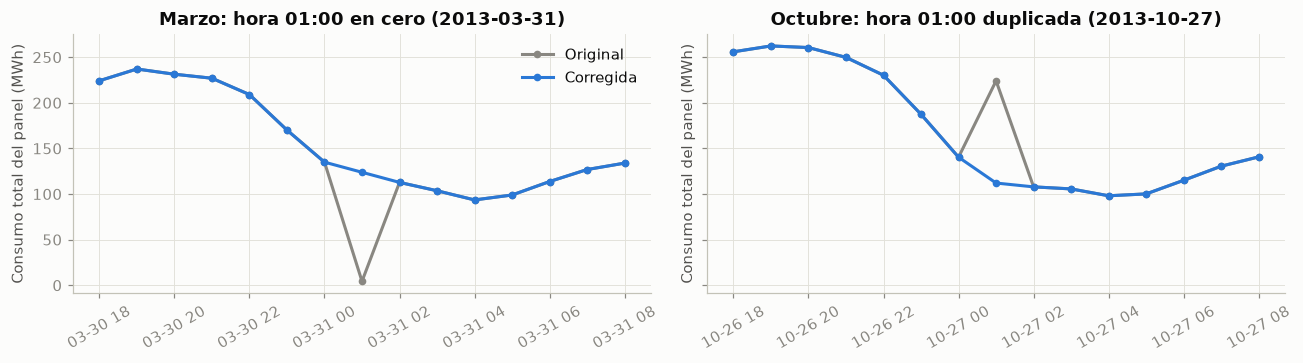

In [8]:
hourly_raw = D.to_hourly(raw, clients)
hourly = D.fix_dst(hourly_raw)
dst = D.dst_days()
print("Días de cambio de horario:", {k: [d.date().isoformat() for d in v] for k, v in dst.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, day, title in [(axes[0], dst["spring"][1], "Marzo: hora 01:00 en cero"),
                       (axes[1], dst["autumn"][1], "Octubre: hora 01:00 duplicada")]:
    sl = slice(day - pd.Timedelta(hours=6), day + pd.Timedelta(hours=8))
    ax.plot(hourly_raw.loc[sl].sum(axis=1) / 1e3, color=GRAY, marker="o", ms=4, label="Original")
    ax.plot(hourly.loc[sl].sum(axis=1) / 1e3, color=PALETTE[0], marker="o", ms=4, label="Corregida")
    ax.set_title(f"{title} ({day.date()})")
    ax.set_ylabel("Consumo total del panel (MWh)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend()
plt.tight_layout(); savefig(fig, "2_2_cambio_horario"); plt.show()

**Tratamiento:**

- **Marzo:** la hora 01:00 no existió. Se imputa con la media de las horas 00:00 y 02:00 del mismo día, que solo usa vecinos inmediatos.
- **Octubre:** la hora 01:00 contiene dos horas reales, así que se divide entre 2.

Así cada serie conserva una rejilla regular de 24 horas por día en hora local. Es la escala que siguen los hábitos de consumo y las covariables de calendario, y evita huecos o duplicados que romperían las ventanas deslizantes.

### 2.3 Perfiles promedio y feriados de Portugal
### Grafiquen el perfil promedio por hora del día y por día de la semana, y marquen los feriados de Portugal. ¿Cómo cambia el consumo en Navidad y Año Nuevo?

Las escalas de los clientes difieren en órdenes de magnitud, así que para promediar perfiles dividimos cada serie entre su consumo medio. Un valor de 1.0 equivale al consumo promedio del cliente.

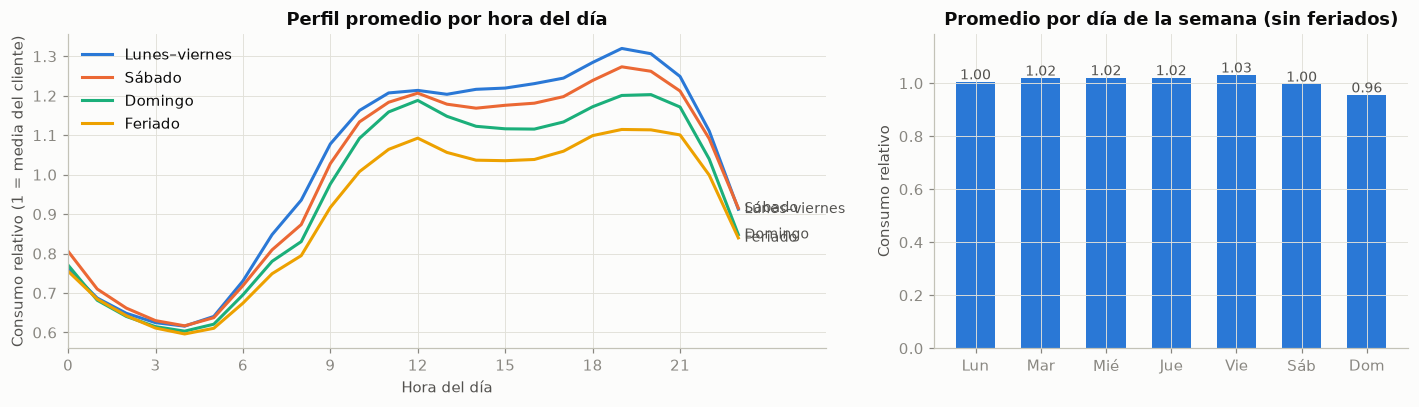

In [9]:
hol = D.portugal_holidays()
hol_days = pd.DatetimeIndex(hol.index)
rel = hourly / hourly.loc[:C.TRAIN_END].mean()          # consumo relativo de cada cliente
panel_rel = rel.mean(axis=1)                             # perfil relativo promedio del panel
is_hol = panel_rel.index.normalize().isin(hol_days)
dow = panel_rel.index.dayofweek
day_type = np.select([is_hol, dow == 6, dow == 5], ["Feriado", "Domingo", "Sábado"], "Lunes–viernes")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for k, name in enumerate(["Lunes–viernes", "Sábado", "Domingo", "Feriado"]):
    prof = panel_rel[day_type == name].groupby(panel_rel[day_type == name].index.hour).mean()
    ax.plot(prof.index, prof.values, color=PALETTE[k], label=name)
    ax.annotate(name, (23, prof.iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=9, color="#52514e")
ax.set_xlabel("Hora del día"); ax.set_ylabel("Consumo relativo (1 = media del cliente)")
ax.set_title("Perfil promedio por hora del día"); ax.set_xticks(range(0, 24, 3)); ax.set_xlim(0, 26)
ax.legend(loc="upper left")

ax = axes[1]
by_dow = panel_rel[~is_hol].groupby(dow[~is_hol]).mean()
ax.bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], by_dow.values, color=PALETTE[0], width=0.6)
for x, v in enumerate(by_dow.values):
    ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color="#52514e")
ax.set_ylim(0, by_dow.max() * 1.15); ax.set_title("Promedio por día de la semana (sin feriados)")
ax.set_ylabel("Consumo relativo")
plt.tight_layout(); savefig(fig, "2_3_perfiles"); plt.show()

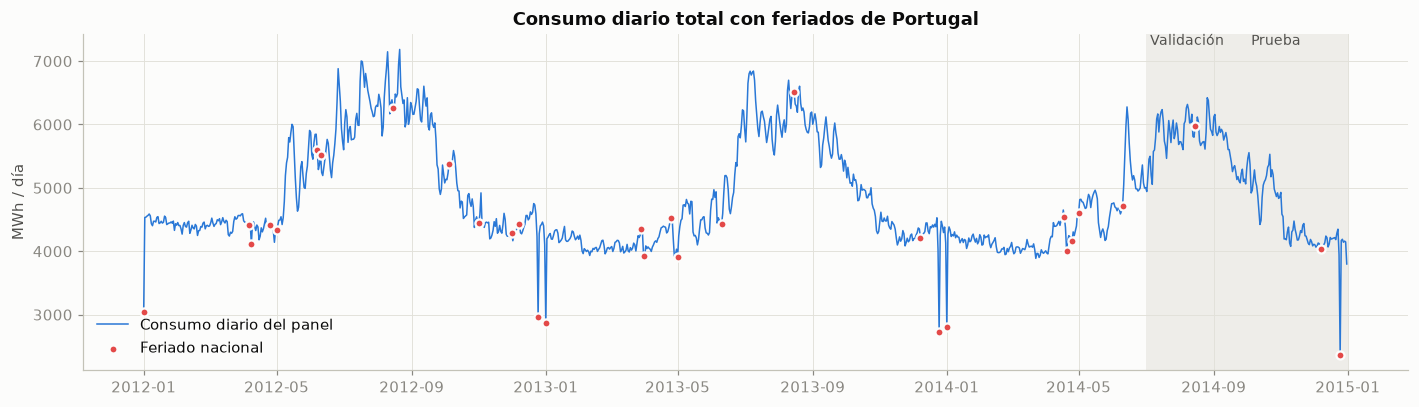

2012    13
2013     9
2014     9


In [10]:
daily = hourly.sum(axis=1).resample("D").sum() / 1e3       # MWh por día, todo el panel
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(daily.index, daily.values, color=PALETTE[0], lw=1, label="Consumo diario del panel")
ax.scatter(hol_days, daily.reindex(hol_days).values, color=PALETTE[7], s=28, zorder=3,
           edgecolor="#fcfcfb", linewidth=1.5, label="Feriado nacional")
for a, b, name in [(C.VAL_START, C.VAL_END, "Validación"), (C.TEST_START, C.TEST_END, "Prueba")]:
    ax.axvspan(a, b, color="#e1e0d9", alpha=0.5, lw=0)
    ax.text(a + pd.Timedelta(days=4), daily.max() * 1.01, name, fontsize=9, color="#52514e")
ax.set_ylabel("MWh / día"); ax.set_title("Consumo diario total con feriados de Portugal")
ax.legend(loc="lower left")
plt.tight_layout(); savefig(fig, "2_3_diario_feriados"); plt.show()
print(hol.groupby(hol.index.year).size().rename("feriados por año").to_string())

año,2012,2013,2014
día,,,
23 dic,+5.2%,+7.7%,+5.3%
24 dic (Nochebuena),-2.3%,-5.5%,-4.2%
25 dic (Navidad),-32.4%,-36.0%,-42.7%
26 dic,-2.4%,-1.1%,-0.5%
31 dic,-5.0%,-2.1%,-6.8%
1 ene (Año Nuevo),-35.3%,-34.9%,fuera del panel


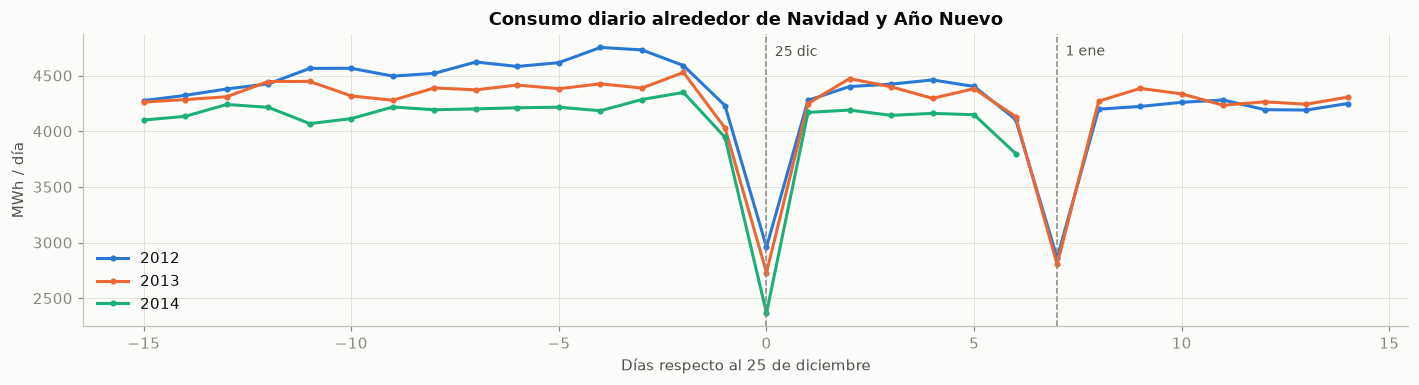

In [11]:
# Navidad y Año Nuevo: cada día comparado con el mismo día de la semana en las 4 semanas previas
# (la referencia excluye feriados).
def vs_typical(day):
    day = pd.Timestamp(day)
    refs = [day - pd.Timedelta(weeks=k) for k in range(1, 5)]
    refs = [r for r in refs if r not in hol_days]
    return daily.loc[day] / daily.loc[refs].mean() - 1

rows = []
for y in (2012, 2013, 2014):
    for label, md_ in [("23 dic", "12-23"), ("24 dic (Nochebuena)", "12-24"), ("25 dic (Navidad)", "12-25"),
                       ("26 dic", "12-26"), ("31 dic", "12-31"), ("1 ene (Año Nuevo)", "01-01")]:
        d = pd.Timestamp(f"{y + 1 if md_ == '01-01' else y}-{md_}")
        if d in daily.index:
            rows.append({"año": y, "día": label, "variación vs típico": vs_typical(d)})
xmas_tab = pd.DataFrame(rows).pivot(index="día", columns="año", values="variación vs típico")
display(xmas_tab.loc[[r for r in ["23 dic", "24 dic (Nochebuena)", "25 dic (Navidad)", "26 dic", "31 dic",
                                  "1 ene (Año Nuevo)"] if r in xmas_tab.index]].style.format("{:+.1%}", na_rep="fuera del panel"))

fig, ax = plt.subplots(figsize=(13, 3.6))
for k, y in enumerate((2012, 2013, 2014)):
    s = daily.loc[f"{y}-12-10":f"{y + 1}-01-08"] if y < 2014 else daily.loc[f"{y}-12-10":f"{y}-12-31"]
    ax.plot((s.index - pd.Timestamp(f"{y}-12-25")).days, s.values, color=PALETTE[k], marker="o", ms=3, label=str(y))
for x, name in [(0, "25 dic"), (7, "1 ene")]:
    ax.axvline(x, color=GRAY, lw=1, ls="--")
    ax.text(x + 0.2, ax.get_ylim()[1] * 0.98, name, fontsize=9, color="#52514e", va="top")
ax.set_xlabel("Días respecto al 25 de diciembre"); ax.set_ylabel("MWh / día")
ax.set_title("Consumo diario alrededor de Navidad y Año Nuevo"); ax.legend()
plt.tight_layout(); savefig(fig, "2_3_navidad"); plt.show()

**Navidad y Año Nuevo.** Cada día se compara con el mismo día de la semana en las 4 semanas previas.

- **25 de diciembre:** el consumo del panel cae entre **32% y 43%**. Es la caída más fuerte del año.
- **1 de enero:** cae alrededor de **35%**. El 1 de enero de 2015 queda fuera del panel.
- **24 y 31 de diciembre:** solo bajan entre 2% y 7%. No son feriados en Portugal.
- **26 de diciembre:** es prácticamente un día normal, entre −0.5% y −2.4%.
- **23 de diciembre:** sube entre **5% y 8%**, posiblemente por la actividad previa al feriado.

Implicaciones para el modelado:

- **Un seasonal naive semanal copia la semana anterior**, así que sobreestima el 25 de diciembre en 50–75%.
- **Hay pocos ejemplos para aprender el efecto.** El entrenamiento solo contiene **dos Navidades** (2012 y 2013), y la variable `holiday` marca apenas 13, 9 y 9 días por año. Hay menos feriados en 2013–2014 porque Portugal suspendió 4 de ellos en esos años.

### 2.4 Escalas entre clientes y normalización

### ¿Qué tan distintas son las escalas entre clientes (mínimo, mediana y máximo del consumo promedio)? Propongan y justifiquen una normalización: global, por serie (z-score con estadísticos de entrenamiento) o por ventana

Consumo medio por cliente (kWh/h), entrenamiento:
  mínimo        4.33  (MT_003)
  mediana     148.19
  máximo    48817.77  (MT_362)
  razón máximo / mínimo: 11,271x
  los 10 clientes más grandes suman el 53% del consumo total


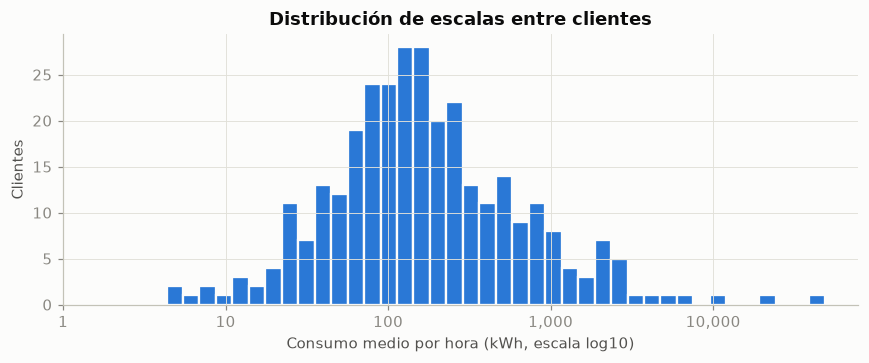

In [12]:
panel = D.Panel.from_wide(hourly)
stats = D.series_stats(panel)            # media, desviación y escala del MASE, SOLO con entrenamiento
m = stats.set_index("unique_id")["mean"]
print(f"Consumo medio por cliente (kWh/h), entrenamiento:")
print(f"  mínimo  {m.min():10.2f}  ({m.idxmin()})")
print(f"  mediana {m.median():10.2f}")
print(f"  máximo  {m.max():10.2f}  ({m.idxmax()})")
print(f"  razón máximo / mínimo: {m.max() / m.min():,.0f}x")
top10 = m.sort_values(ascending=False).head(10).sum() / m.sum()
print(f"  los 10 clientes más grandes suman el {top10:.0%} del consumo total")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.log10(m), bins=40, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=1.5)
ax.set_xlabel("Consumo medio por hora (kWh, escala log10)")
ax.set_xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1,000", "10,000"])
ax.set_ylabel("Clientes"); ax.set_title("Distribución de escalas entre clientes")
plt.tight_layout(); savefig(fig, "2_4_escalas"); plt.show()

**Escalas.**

- El consumo medio va de 4.33 kWh/h (MT_003) a 48,818 kWh/h (MT_362), una razón de 11,271×.
- Los 10 clientes más grandes suman el 53% del consumo.

Consecuencias:

1. MAE y RMSE quedan dominados por los clientes grandes. En la tabla final el RMSE (370 kWh) es 8 veces el MAE (43 kWh). Esa distancia la producen los errores de pocas series enormes.
2. Sin normalizar, la pérdida solo aprende de los clientes grandes. Un error de 1% en MT_362 pesa lo mismo que equivocarse por completo en cientos de clientes pequeños. Por eso cada ventana se normaliza antes de entrar a la red, y la predicción se desnormaliza después.
3. La métrica principal es el MASE, que no depende de la escala: divide entre el error del seasonal naive de cada cliente. MAE y WAPE se reportan como complemento en kWh.

#### 2.4.1 Comprobación empírica de la normalización

Entrenamos el mismo MLP con las tres normalizaciones y comparamos solo en validación, la prueba no se toca. Las clases se definen más abajo (sección 5) y aquí se importan por adelantado. Estas corridas también quedan en `results/runs.csv` como iteraciones de hiperparámetros.

In [13]:
from lab9 import dataset as DS, models as MD, training as TR

panel_fit = panel.until(C.VAL_END)        # lo único que ve el entrenamiento: entrenamiento + validación
QK = dict(max_epochs=1, samples_per_epoch=5_000) if QUICK else dict(max_epochs=15, patience=4, samples_per_epoch=150_000)
norm_rows = []
for norm in ["series", "global", "window"]:
    print(f"MLP con normalización '{norm}'")
    m_ = TR.TorchForecaster(f"MLP_norm_{norm}", partial(MD.build_mlp, hidden=512, n_layers=2, dropout=0.1),
                            norm=norm, family="MLP", verbose=False, **QK)
    m_.fit(panel_fit, C.VAL_START)
    TR.save_run(m_)
    norm_rows.append({"norm": norm, "best_epoch": m_.best_epoch, "val_MAE": m_.best_val["val_MAE"],
                      "val_MASE": m_.best_val["val_MASE"], "train_time_s": m_.train_time})
norm_tab = pd.DataFrame(norm_rows).set_index("norm")
display(norm_tab.round(3))
NORM = norm_tab["val_MASE"].idxmin()
print("Normalización elegida (menor MASE en validación):", NORM)

MLP con normalización 'series'


MLP con normalización 'global'


MLP con normalización 'window'


,best_epoch,val_MAE,val_MASE,train_time_s
norm,,,,
series,14,51.071,0.883,176.131
global,5,87.847,3.228,88.377
window,7,50.500,0.877,65.871


Normalización elegida (menor MASE en validación): window


**Resultado (validación, MLP idéntico).**

- **Global:** falla con claridad (MASE 3.23). Con una sola media y desviación para todo el panel, los clientes pequeños quedan en un rango diminuto alrededor de un mismo valor. La red prácticamente no los distingue.
- **Por serie:** MASE 0.883.
- **Por ventana:** MASE 0.877. Es tipo RevIN: usa la media y desviación de la propia ventana de entrada.
  - Además converge en menos tiempo (66 s contra 176 s).
  - También se adapta si un cliente cambia de nivel durante el periodo.
  - Se tomó **window**, siguiendo la regla de menor MASE en validación.

La diferencia entre *window* y *series* (0.006) es pequeña. Viene de una sola semilla y conviene leerla como empate técnico. Lo que sí es concluyente es que normalizar **por cliente** es indispensable.

### 2.5 Covariables de calendario conocidas a futuro

| Variable | Codificación | Motivo |
|---|---|---|
| Hora (0–23) | `sin(2πh/24)`, `cos(2πh/24)` | Cíclica: 23:00 queda junto a 00:00 y bastan 2 columnas en vez de 24 de one-hot |
| Día de la semana (0–6) | `sin(2πd/7)`, `cos(2πd/7)` | Cíclica; domingo queda junto a lunes |
| Mes (0–11) | `sin(2πm/12)`, `cos(2πm/12)` | Cíclica; diciembre queda junto a enero |
| Feriado nacional | 0/1 | Binaria; viene del calendario oficial, que se publica con anticipación |

Todas dependen solo de la fecha, así que se pueden calcular para cualquier hora futura **en el instante del pronóstico**. Para las redes elegimos seno/coseno en lugar de embeddings porque son pocas variables, de baja cardinalidad y periódicas: no hay nada que aprender en la codificación. LightGBM, en cambio, recibe hora, día y mes como enteros, porque los árboles cortan umbrales sin problema.

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,holiday
2014-12-24 22:00:00,-0.500,0.866,0.975,-0.223,-0.5,0.866,0.0
2014-12-24 23:00:00,-0.259,0.966,0.975,-0.223,-0.5,0.866,0.0
2014-12-25 00:00:00,0.000,1.000,0.434,-0.901,-0.5,0.866,1.0
2014-12-25 01:00:00,0.259,0.966,0.434,-0.901,-0.5,0.866,1.0
2014-12-25 02:00:00,0.500,0.866,0.434,-0.901,-0.5,0.866,1.0


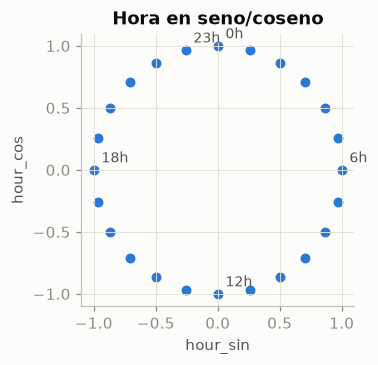

In [14]:
cal = D.calendar_features(panel.times)
display(cal.loc["2014-12-24 22:00":"2014-12-25 02:00"].round(3))
fig, ax = plt.subplots(figsize=(3.6, 3.6))
h = np.arange(24)
ax.scatter(np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24), color=PALETTE[0], s=30)
for hh in (0, 6, 12, 18, 23):
    ax.annotate(f"{hh}h", (np.sin(2 * np.pi * hh / 24), np.cos(2 * np.pi * hh / 24)), xytext=(5, 5),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set_aspect("equal"); ax.set_xlabel("hour_sin"); ax.set_ylabel("hour_cos"); ax.set_title("Hora en seno/coseno")
plt.tight_layout(); savefig(fig, "2_5_hora_sincos"); plt.show()

#### 2.5.1 Exportación del panel limpio

La Parte 2 lee estos archivos; así todos los modelos usan exactamente el mismo panel de clientes.

In [15]:
long = D.to_long(hourly)
long.to_parquet(C.HOURLY_PATH, index=False)
pd.Series(clients, name="unique_id").to_csv(C.CLIENTS_PATH, index=False)
stats.to_csv(C.STATS_PATH, index=False)
hol.rename_axis("fecha").rename("feriado").to_csv(C.DATA_DIR / "holidays_pt.csv")
print(long.shape, "->", C.HOURLY_PATH.relative_to(C.ROOT))
display(long.head())
# Comprobación: el panel se reconstruye idéntico desde el parquet
assert np.allclose(D.load_panel().Y, panel.Y)

(8285760, 3) -> data\hourly.parquet


,unique_id,ds,y
0,MT_001,2012-01-01 00:00:00,3.172589
1,MT_001,2012-01-01 01:00:00,4.124365
2,MT_001,2012-01-01 02:00:00,4.758883
3,MT_001,2012-01-01 03:00:00,4.441624
4,MT_001,2012-01-01 04:00:00,4.758883


### 2.6 Dataset de ventanas deslizantes

`WindowDataset` recorre **todas las series** y genera ventanas `(serie, inicio del objetivo s)`:

- `x`: `(L, 8)`, con la serie normalizada más las 7 covariables de calendario de las horas `s-L … s-1`;
- `x_fut`: `(H, 7)`, el calendario de las horas a pronosticar (conocido a futuro);
- `y`: `(H,)`, el objetivo normalizado en `s … s+H-1`.

Una ventana pertenece a una partición si **todo su objetivo** cae dentro de ella. La entrada puede venir de antes, porque es pasado. Implementa `__getitems__` para que el `DataLoader` arme cada batch con una sola indexación vectorizada.

In [ ]:
%%writefile lab9/dataset.py
"""Etapa 3 del pipeline: series horarias -> ventanas deslizantes -> tensores."""
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

from . import config as C

NORMS = ("series", "global", "window", "none")


def norm_params(panel_train, norm):
    """Parámetros de normalización estimados SOLO con el panel de entrenamiento recibido.

    Devuelve (loc, scale) por serie, de forma (N,). Para 'window' la media/desviación se
    calculan en cada ventana de entrada; aquí solo se devuelve la desviación de
    entrenamiento, que se usa como piso para no dividir entre ~0.
    """
    Y = panel_train.Y
    if norm == "series":
        return Y.mean(axis=1), Y.std(axis=1) + 1e-6
    if norm == "global":
        return np.full(len(Y), Y.mean()), np.full(len(Y), Y.std())
    if norm == "window":
        return np.zeros(len(Y)), 0.1 * Y.std(axis=1) + 1e-6
    if norm == "none":
        return np.zeros(len(Y)), np.ones(len(Y))
    raise ValueError(f"norm debe ser uno de {NORMS}")


class WindowDataset(Dataset):
    """Ventanas deslizantes sobre TODAS las series del panel.

    Solo se generan ventanas cuyo objetivo cae completo dentro de [first_target, last_target];
    la entrada puede venir de antes (es pasado). `stride` es el paso entre orígenes
    consecutivos (1 = cada hora, 24 = un origen por día a las 00:00).
    `history_months` limita los datos usados (entrada + objetivo) a los últimos M meses.
    """

    def __init__(self, panel, L, H, first_target, last_target, loc, scale, norm="series",
                 stride=1, history_months=None):
        last_pos = panel.idx(last_target)
        # El panel se trunca en el último objetivo: es imposible leer datos posteriores.
        panel = panel.until(last_target)
        first_pos = panel.idx(first_target)
        min_input = 0
        if history_months is not None:
            data_start = pd.Timestamp(last_target) - pd.DateOffset(months=history_months) + pd.Timedelta(hours=1)
            min_input = max(0, int(np.searchsorted(panel.times, data_start)))
        s0 = max(first_pos, min_input + L)
        self.starts = np.arange(s0, last_pos - H + 2, stride)
        self.L, self.H, self.norm = L, H, norm
        self.times = panel.times
        self.Y = torch.as_tensor(panel.Y, dtype=torch.float32)               # (N, T)
        self.cal = torch.as_tensor(panel.cal, dtype=torch.float32)           # (T, n_cal)
        self.loc = torch.as_tensor(np.asarray(loc), dtype=torch.float32)
        self.scale = torch.as_tensor(np.asarray(scale), dtype=torch.float32)
        self.n_series = self.Y.shape[0]
        self.n_per_series = len(self.starts)
        self.n_features = 1 + self.cal.shape[1]
        self._in = torch.arange(-L, 0)
        self._out = torch.arange(0, H)

    def __len__(self):
        return self.n_series * self.n_per_series

    def __getitem__(self, i):
        x, xf, y, loc, scale, sid = self.__getitems__([i])
        return x[0], xf[0], y[0], loc[0], scale[0], sid[0]

    def __getitems__(self, idx):
        """Versión vectorizada: el DataLoader la usa para armar el batch completo de una vez."""
        idx = torch.as_tensor(idx, dtype=torch.long)
        sid = idx // self.n_per_series
        s = torch.as_tensor(self.starts)[idx % self.n_per_series]
        pin = s[:, None] + self._in                                          # (B, L)
        pout = s[:, None] + self._out                                        # (B, H)
        y_in = self.Y[sid[:, None], pin]
        y_out = self.Y[sid[:, None], pout]
        if self.norm == "window":
            # Estadísticos de la propia ventana de entrada (disponibles en el origen).
            loc = y_in.mean(dim=1)
            scale = torch.maximum(y_in.std(dim=1), self.scale[sid])
        else:
            loc, scale = self.loc[sid], self.scale[sid]
        y_in = (y_in - loc[:, None]) / scale[:, None]
        y_out = (y_out - loc[:, None]) / scale[:, None]
        x = torch.cat([y_in[..., None], self.cal[pin]], dim=-1)
        xf = self.cal[pout]
        return x, xf, y_out, loc, scale, sid

    def target_times(self, i):
        s = self.starts[i % self.n_per_series]
        return self.times[s:s + self.H]


def collate_batch(batch):
    """__getitems__ ya devuelve tensores apilados; el collate no tiene que hacer nada."""
    return batch


def make_inputs(y_hist, times_hist, times_future, L, loc, scale, norm, cal_fn):
    """Arma (x, x_fut, loc, scale) para inferencia en un origen, con la misma lógica que el Dataset.

    y_hist: (N, t) en kWh con t >= L, solo datos anteriores al origen.
    """
    y_in = torch.as_tensor(np.asarray(y_hist[:, -L:]), dtype=torch.float32)
    loc = torch.as_tensor(np.asarray(loc), dtype=torch.float32)
    scale = torch.as_tensor(np.asarray(scale), dtype=torch.float32)
    if norm == "window":
        loc = y_in.mean(dim=1)
        scale = torch.maximum(y_in.std(dim=1), scale)
    y_in = (y_in - loc[:, None]) / scale[:, None]
    N = y_in.shape[0]
    cal_in = torch.as_tensor(cal_fn(times_hist[-L:]).values).expand(N, -1, -1)
    cal_out = torch.as_tensor(cal_fn(times_future).values).expand(N, -1, -1)
    x = torch.cat([y_in[..., None], cal_in], dim=-1)
    return x, cal_out.contiguous(), loc, scale


def count_windows(panel, L=168, H=C.H, stride=1):
    """Número de ventanas por partición con stride dado (objetivo completo dentro del bloque)."""
    rows = []
    for split, a, b in [("train", C.START, C.TRAIN_END), ("val", C.VAL_START, C.VAL_END),
                        ("test", C.TEST_START, C.TEST_END)]:
        ds = WindowDataset(panel, L, H, a, b, np.zeros(panel.N), np.ones(panel.N), "none", stride)
        rows.append({"split": split, "stride": stride, "por_serie": ds.n_per_series,
                     "panel": len(ds)})
    return pd.DataFrame(rows)


Overwriting lab9/dataset.py


In [17]:
from torch.utils.data import DataLoader

loc, scale = DS.norm_params(panel.until(C.TRAIN_END), "series")
train_ds = DS.WindowDataset(panel, 168, C.H, C.START, C.TRAIN_END, loc, scale, "series", stride=1)
dl = DataLoader(train_ds, batch_size=256, shuffle=True, collate_fn=DS.collate_batch)
x, xf, y, loc_b, scale_b, sid = next(iter(dl))
print("X     :", tuple(x.shape), " (batch, L, features)")
print("x_fut :", tuple(xf.shape), " (batch, H, covariables de calendario)")
print("y     :", tuple(y.shape), "  (batch, H)")

counts = pd.concat([DS.count_windows(panel, L=168, H=24, stride=1),
                    DS.count_windows(panel, L=168, H=24, stride=24)], ignore_index=True)
display(counts)

X     : (256, 168, 8)  (batch, L, features)
x_fut : (256, 24, 7)  (batch, H, covariables de calendario)
y     : (256, 24)   (batch, H)


,split,stride,por_serie,panel
0,train,1,21697,6834555
1,val,1,2185,688275
2,test,1,2185,688275
3,train,24,905,285075
4,val,24,92,28980
5,test,24,92,28980


**Ventanas.**

- **Tensores por batch:** `X` (256, 168, 8), `x_fut` (256, 24, 7) e `y` (256, 24).
- **Stride 1:** hay 21,697 ventanas de entrenamiento por serie, **6.83 millones** en el panel. Validación y prueba tienen 2,185 por serie cada una.
- **Las ventanas consecutivas se solapan casi por completo** (comparten 167 de 168 horas). Recorrer los 6.8 M en cada epoch sería muy redundante. Por eso cada epoch muestrea **200,000 ventanas al azar con reemplazo**.
- **Validación y prueba usan stride 24:** un origen por día a las 00:00, es decir 92 orígenes × 315 clientes = 28,980 ventanas. Es exactamente el mismo protocolo del backtest, así que el early stopping optimiza lo mismo que luego se evalúa.
- **Fugas:** las cuatro auditorías de abajo pasan. Revisan la partición temporal, los estadísticos de entrenamiento, que `predict` reciba solo el pasado, y la alineación entrada/objetivo/calendario.

### 2.7 Auditoría de fugas

Regla: cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico (00:00 del día pronosticado, con datos hasta las 23:00 del día anterior). Para cada una de las cuatro fugas vistas en clase mostramos con código cómo la evita el pipeline.

#### 2.7.1 Fuga 1: split aleatorio de ventanas
Si las ventanas se mezclan antes de partir, una ventana de entrenamiento puede contener el futuro de una de validación o de prueba. Aquí la partición es temporal por construcción: cada `WindowDataset` recibe un rango de fechas para el objetivo y el `shuffle` solo ocurre *dentro* de la partición de entrenamiento.

In [18]:
loc, scale = DS.norm_params(panel.until(C.TRAIN_END), "series")
splits = {name: DS.WindowDataset(panel, 168, 24, a, b, loc, scale, "series", stride=1)
          for name, a, b in [("train", C.START, C.TRAIN_END), ("val", C.VAL_START, C.VAL_END),
                             ("test", C.TEST_START, C.TEST_END)]}
rng_tab = []
for name, ds_ in splits.items():
    first_t = ds_.target_times(0)[0]
    last_t = ds_.target_times(ds_.n_per_series - 1)[-1]
    rng_tab.append({"split": name, "primer objetivo": first_t, "último objetivo": last_t,
                    "última hora del panel interno": ds_.times[-1]})
rng_tab = pd.DataFrame(rng_tab); display(rng_tab)
# Los objetivos de cada partición son estrictamente posteriores a los de la anterior.
assert rng_tab.loc[0, "último objetivo"] < rng_tab.loc[1, "primer objetivo"]
assert rng_tab.loc[1, "último objetivo"] < rng_tab.loc[2, "primer objetivo"]
# El dataset de entrenamiento ni siquiera contiene datos posteriores a TRAIN_END (se trunca el panel).
assert splits["train"].times[-1] == C.TRAIN_END and splits["train"].Y.shape[1] == panel.idx(C.TRAIN_END) + 1
print("OK: partición temporal; el dataset de entrenamiento no contiene ninguna hora de validación o prueba.")

,split,primer objetivo,último objetivo,última hora del panel interno
0,train,2012-01-08,2014-06-30 23:00:00,2014-06-30 23:00:00
1,val,2014-07-01,2014-09-30 23:00:00,2014-09-30 23:00:00
2,test,2014-10-01,2014-12-31 23:00:00,2014-12-31 23:00:00


OK: partición temporal; el dataset de entrenamiento no contiene ninguna hora de validación o prueba.


#### 2.7.2 Fuga 2: escalar con toda la serie
Si la media y la desviación se calculan con toda la serie, el nivel de la prueba (por ejemplo, el aumento del invierno) se filtra al entrenamiento. Aquí `norm_params` y `series_stats` reciben `panel.until(TRAIN_END)`. Para demostrarlo, multiplicamos por 10 todos los datos posteriores al entrenamiento y verificamos que los estadísticos no cambian.

In [19]:
corrupt = D.Panel(panel.Y.copy(), panel.times, panel.ids, panel.cal)
corrupt.Y[:, panel.idx(C.VAL_START):] *= 10                         # alteramos validación y prueba
loc_a, scale_a = DS.norm_params(panel.until(C.TRAIN_END), "series")
loc_b, scale_b = DS.norm_params(corrupt.until(C.TRAIN_END), "series")
assert np.allclose(loc_a, loc_b) and np.allclose(scale_a, scale_b)
assert np.allclose(D.series_stats(panel)["mase_scale"], D.series_stats(corrupt)["mase_scale"])
# En contraste, escalar con toda la serie sí habría cambiado:
leaky = panel.Y.mean(axis=1)
print(f"Diferencia media entre la media de entrenamiento y la de toda la serie: "
      f"{np.mean(np.abs(leaky / loc_a - 1)):.1%}")
print("OK: los estadísticos de normalización y del MASE solo dependen del bloque de entrenamiento.")

Diferencia media entre la media de entrenamiento y la de toda la serie: 1.2%
OK: los estadísticos de normalización y del MASE solo dependen del bloque de entrenamiento.


#### 2.7.3 Fuga 3: early stopping con la prueba
Si se elige la epoch (o la configuración) mirando la prueba, el error reportado es optimista. La función `backtest` entrena una vez con `panel.until(VAL_END)` y le indica a `fit` dónde empieza validación. Además, en cada origen `predict` solo recibe `Y[:, :origen]`. Lo comprobamos con un modelo espía que registra la última marca que recibe en cada llamada.

In [20]:
%%writefile lab9/backtest.py
"""Protocolo único de evaluación: backtesting con origen móvil diario.

Contrato que cumple todo modelo (propio o envoltorio de librería):

    model.name : str
    model.fit(panel, val_start)            -> panel ya truncado; val_start marca el bloque de
                                              validación (early stopping) dentro de ese panel
    model.predict(y_hist, times_hist, times_future)
        y_hist      : (N, t) kWh, SOLO datos anteriores al origen
        times_hist  : marcas de esas t horas
        times_future: las H horas a pronosticar (para covariables de calendario)
        -> ndarray (N, H) en kWh, o dict {"mean": (N, H), "q0.1": (N, H), ...}
"""
import time

import numpy as np
import pandas as pd

from . import config as C


def daily_origins(start, end, H=C.H):
    """Orígenes a las 00:00 de cada día cuyo horizonte completo cabe en [start, end]."""
    days = pd.date_range(start, end, freq="D")
    return [d for d in days if d + pd.Timedelta(hours=H - 1) <= end]


SPLITS = {"val": (C.VAL_START, C.VAL_END), "test": (C.TEST_START, C.TEST_END)}


def _to_long(pred, ids, times_future, cutoff, y_true):
    if not isinstance(pred, dict):
        pred = {"mean": pred}
    N, H = pred["mean"].shape
    df = pd.DataFrame({
        "unique_id": np.repeat(ids, H),
        "ds": np.tile(times_future, N),
        "cutoff": cutoff,
        "h": np.tile(np.arange(1, H + 1), N),
        "y": y_true.reshape(-1),
        "y_hat": np.asarray(pred["mean"]).reshape(-1),
    })
    for k, v in pred.items():
        if k != "mean":
            df[k] = np.asarray(v).reshape(-1)
    return df


def backtest(model, panel, split="test", H=C.H, fit=True, refit_every=None, val_months=3,
             verbose=True):
    """Evalúa `model` con origen móvil diario sobre el bloque `split` ('val' o 'test').

    - fit=True entrena UNA vez con panel.until(VAL_END) (entrenamiento + validación para early
      stopping). La prueba nunca se entrega a fit().
    - refit_every='MS' reentrena al inicio de cada mes con ventana expandible: en el origen o
      se llama fit(panel.until(o - 1h), val_start=o - val_months meses).
    - En cada origen el modelo solo recibe y_hist = Y[:, :origen] (datos hasta las 23:00 del día
      anterior) y las marcas de las H horas futuras.
    Devuelve (preds, info): preds en formato largo y info con tiempos de entrenamiento/inferencia.
    """
    start, end = SPLITS[split]
    origins = daily_origins(start, end, H)
    info = {"model": model.name, "split": split, "n_origins": len(origins), "fit_time_s": 0.0,
            "infer_time_s": 0.0, "n_fits": 0}

    def _fit(cutoff, val_start):
        t0 = time.perf_counter()
        model.fit(panel.until(cutoff), val_start)
        info["fit_time_s"] += time.perf_counter() - t0
        info["n_fits"] += 1

    if fit and refit_every is None:
        _fit(C.VAL_END, C.VAL_START)

    def _inputs(o):
        pos = panel.idx(o)
        # Todo lo anterior al origen y nada más; más las marcas de las H horas futuras.
        return panel.Y[:, :pos], panel.times[:pos], panel.times[pos:pos + H]

    frames = []
    if hasattr(model, "predict_many") and refit_every is None:
        # Modelos locales de StatsForecast: mismos insumos por origen, un solo pool de procesos.
        inputs = [_inputs(o) for o in origins]
        t0 = time.perf_counter()
        preds_all = model.predict_many(inputs)
        info["infer_time_s"] += time.perf_counter() - t0
        for o, (_, _, tf), pred in zip(origins, inputs, preds_all):
            pos = panel.idx(o)
            frames.append(_to_long(pred, panel.ids, tf, o - pd.Timedelta(hours=1), panel.Y[:, pos:pos + H]))
    else:
        for o in origins:
            if refit_every is not None and (o == origins[0] or o.is_month_start):
                cutoff = o - pd.Timedelta(hours=1)
                _fit(cutoff, o - pd.DateOffset(months=val_months))
            y_hist, times_hist, times_future = _inputs(o)
            t0 = time.perf_counter()
            pred = model.predict(y_hist, times_hist, times_future)
            info["infer_time_s"] += time.perf_counter() - t0
            pos = panel.idx(o)
            frames.append(_to_long(pred, panel.ids, times_future, o - pd.Timedelta(hours=1),
                                   panel.Y[:, pos:pos + H]))
    preds = pd.concat(frames, ignore_index=True)
    preds["model"] = model.name
    if verbose:
        print(f"[{model.name}] {split}: {len(origins)} orígenes | fit {info['fit_time_s']:.1f}s "
              f"| inferencia {info['infer_time_s']:.1f}s")
    return preds, info


Overwriting lab9/backtest.py


In [21]:
from lab9 import backtest as BT


class Spy:
    """Modelo trivial (repite el último valor) que anota qué datos recibe."""
    name = "spy"

    def fit(self, panel_, val_start):
        self.fit_last, self.fit_val = panel_.times[-1], val_start
        self.seen = []

    def predict(self, y_hist, times_hist, times_future):
        assert y_hist.shape[1] == len(times_hist)
        self.seen.append((times_hist[-1], times_future[0]))
        return np.repeat(y_hist[:, -1:], len(times_future), axis=1)


spy = Spy()
_ = BT.backtest(spy, panel, split="test", verbose=False)
print("fit() vio datos hasta:", spy.fit_last, "| validación (early stopping) desde:", spy.fit_val)
assert spy.fit_last == C.VAL_END < C.TEST_START
assert all(last == first - pd.Timedelta(hours=1) for last, first in spy.seen)
print(f"OK: en los {len(spy.seen)} orígenes de prueba, predict() solo recibió datos hasta las 23:00 del día anterior.")

fit() vio datos hasta: 2014-09-30 23:00:00 | validación (early stopping) desde: 2014-07-01 00:00:00
OK: en los 92 orígenes de prueba, predict() solo recibió datos hasta las 23:00 del día anterior.


#### 2.7.4 Fuga 4: covariables mal alineadas
Un desfase de una hora entre la serie y las covariables (o usar como entrada algo que solo se conoce después del origen) hace que la red "vea" el futuro. Verificamos tres cosas sobre ventanas tomadas al azar:

1. el último valor de la entrada es la hora `s-1` y el objetivo empieza en `s`;
2. el calendario de `x` y de `x_fut` corresponde exactamente a esas horas;
3. si reemplazamos con NaN todo lo posterior al origen, las entradas que arma `make_inputs` (la misma función que usan las redes en `predict`) no cambian.

In [22]:
ds_ = splits["test"]
rng = np.random.default_rng(0)
for i in rng.integers(0, len(ds_), 5):
    x, xf, y, loc_i, scale_i, sid = ds_[int(i)]
    x, xf, y, loc_i, scale_i = x.numpy(), xf.numpy(), y.numpy(), float(loc_i), float(scale_i)
    s = ds_.starts[int(i) % ds_.n_per_series]
    serie = panel.Y[int(sid)]
    assert np.isclose(x[-1, 0] * scale_i + loc_i, serie[s - 1], rtol=1e-4)      # última entrada = s-1
    assert np.allclose(y * scale_i + loc_i, serie[s:s + 24], rtol=1e-4)         # objetivo = s ... s+23
    t_in, t_out = panel.times[s - 168:s], panel.times[s:s + 24]
    assert np.allclose(x[:, 1:], D.calendar_features(t_in).values)               # calendario de la entrada
    assert np.allclose(xf, D.calendar_features(t_out).values)                    # calendario futuro

o = panel.idx(C.TEST_START)
future_nan = panel.Y.copy(); future_nan[:, o:] = np.nan
args = (panel.times[:o], panel.times[o:o + 24], 168, loc, scale, "series", D.calendar_features)
xa, xfa, _, _ = DS.make_inputs(panel.Y[:, :o], *args)
xb, xfb, _, _ = DS.make_inputs(future_nan[:, :o], *args)
assert torch.equal(xa, xb) and torch.equal(xfa, xfb) and not torch.isnan(xb).any()
print("OK: entrada termina en s-1, objetivo inicia en s, calendario alineado y sin dependencia del futuro.")

OK: entrada termina en s-1, objetivo inicia en s, calendario alineado y sin dependencia del futuro.


## 3. Investigación: herramientas para forecasting en PyTorch

Esta sección resume las clases y funciones que usamos para construir, entrenar y evaluar los modelos, y los conceptos que hay detrás. Cada parte explica para qué sirve la herramienta y sus parámetros más importantes. Al final dice cómo la usamos en el laboratorio. Los ejemplos de código son pequeños: solo comprueban lo que dice el texto.

### 3.1 `nn.LSTM` y `nn.GRU`

**Para qué sirven.** Son redes recurrentes: recorren la ventana hora por hora y en cada paso actualizan una memoria con lo que vieron.

- **LSTM:** tiene dos memorias.
  - El **estado oculto** $h_t$ es lo que la red entrega en cada paso.
  - El **estado de celda** $c_t$ es una memoria de largo plazo.
  - Tres compuertas deciden qué entra a la memoria, qué se olvida y qué se muestra (entrada, olvido y salida).
  - Gracias a las compuertas puede recordar información de muchas horas atrás sin que el gradiente se pierda.
- **GRU:** es una versión más simple.
  - Solo tiene el estado oculto $h_t$ y dos compuertas (actualización y reinicio).
  - Tiene aproximadamente 25% menos parámetros que una LSTM del mismo tamaño y entrena un poco más rápido.
  - En muchos problemas da resultados parecidos.

**Parámetros principales**

| Parámetro | Qué controla | En el laboratorio |
|---|---|---|
| `input_size` | Número de variables que entran en cada paso | 8 (consumo normalizado + 7 de calendario) |
| `hidden_size` | Tamaño del estado oculto, la capacidad de la memoria | 128 |
| `num_layers` | Capas recurrentes apiladas. La salida de una capa es la entrada de la siguiente | 2 |
| `batch_first` | Si es `True`, los tensores son `(batch, L, features)`. Por defecto es `False` y el orden es `(L, batch, features)` | `True` |
| `dropout` | Apaga neuronas al azar entre capas para evitar sobreajuste. Se aplica a la salida de cada capa menos la última, así que solo funciona si `num_layers > 1` | 0.1 |

**Forma de las salidas.** La LSTM devuelve `output, (h_n, c_n)` y la GRU devuelve `output, h_n`.

| Salida | Forma | Qué contiene |
|---|---|---|
| `output` | `(batch, L, D * hidden_size)` | El estado oculto de la **última capa** en **cada paso** de la ventana |
| `h_n` | `(D * num_layers, batch, hidden_size)` | El **último** estado oculto de **cada capa** |
| `c_n` | `(D * num_layers, batch, hidden_size)` | El último estado de celda de cada capa (solo LSTM) |

$D = 2$ si la red es bidireccional y $D = 1$ si no lo es. **Ojo:** `h_n` y `c_n` siempre ponen las capas primero, aunque `batch_first=True`. Además, `output[:, -1]` es igual a `h_n[-1]`: el último paso de la última capa.

**Cómo las usamos:**

- **LSTM multi-salida:** toma `h_n[-1]`, lo une con el calendario de las 24 horas futuras y una capa densa devuelve los 24 pasos.
- **Seq2seq:** el `(h_n, c_n)` del encoder es el estado inicial del decoder.

In [ ]:
import torch
from torch import nn

torch.manual_seed(0)
x = torch.randn(32, 168, 8)                         # (batch, L, features), como las ventanas del laboratorio
lstm = nn.LSTM(input_size=8, hidden_size=128, num_layers=2, batch_first=True, dropout=0.1)
gru = nn.GRU(input_size=8, hidden_size=128, num_layers=2, batch_first=True, dropout=0.1)
lstm.eval(); gru.eval()                             # sin dropout para comparar salidas

out, (h_n, c_n) = lstm(x)
out_g, h_g = gru(x)
print("LSTM  output:", tuple(out.shape), "| h_n:", tuple(h_n.shape), "| c_n:", tuple(c_n.shape))
print("GRU   output:", tuple(out_g.shape), "| h_n:", tuple(h_g.shape))
print("output[:, -1] es igual a h_n[-1]:", torch.allclose(out[:, -1], h_n[-1]))
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"Parámetros: LSTM {n_params(lstm):,} | GRU {n_params(gru):,} "
      f"(la GRU tiene 3 bloques de pesos por capa y la LSTM 4)")

LSTM  output: (32, 168, 128) | h_n: (2, 32, 128) | c_n: (2, 32, 128)
GRU   output: (32, 168, 128) | h_n: (2, 32, 128)
output[:, -1] es igual a h_n[-1]: True
Parámetros: LSTM 202,752 | GRU 152,064 (la GRU tiene 3 bloques de pesos por capa y la LSTM 4)


### 3.2 `nn.Conv1d` con dilatación y padding causal (TCN)

**Para qué sirve.** `nn.Conv1d` desliza un filtro a lo largo del tiempo. En cada posición combina unos pocos valores vecinos y devuelve un número. La entrada tiene forma `(batch, canales, tiempo)`. **El tiempo va al final**, al revés que en la LSTM con `batch_first=True`.

**Parámetros principales**

| Parámetro | Qué controla |
|---|---|
| `in_channels` | Número de variables de entrada |
| `out_channels` | Número de filtros, que es el número de variables de salida |
| `kernel_size` ($k$) | Cuántos instantes mira cada filtro |
| `dilation` ($d$) | Separación entre los instantes que mira. Con $k = 3$ y $d = 4$, la salida en $t$ usa $t$, $t-4$ y $t-8$ |
| `padding` | Ceros que se agregan en los bordes para que la salida no se acorte |

**Padding causal.** Al pronosticar, la salida en la hora $t$ solo puede usar $t, t-1, t-2, \dots$ y nunca $t+1$. El `padding` normal de `Conv1d` pone ceros **a los dos lados**, así que la salida en $t$ vería el futuro.

La solución es agregar $(k-1)\,d$ ceros **solo a la izquierda**, con `F.pad`, y no poner padding dentro de la convolución. Así la salida tiene el mismo largo que la entrada y cada valor solo depende del pasado. Otra forma equivalente es usar `padding=(k-1)*d` y recortar los últimos $(k-1)\,d$ valores de la salida.

**Campo receptivo.** Es cuántas horas del pasado puede ver una salida.

- Una capa ve $(k-1)\,d + 1$ horas.
- Al apilar capas, cada una agrega $(k-1)\,d_i$:

$$RF = 1 + \sum_{i} (k-1)\, d_i$$

- Si cada bloque residual tiene dos convoluciones, como en la TCN original (Bai et al., 2018), cada término cuenta dos veces.
- Con dilataciones que se duplican ($1, 2, 4, \dots, 2^{n-1}$) el campo receptivo crece muy rápido con pocas capas: $RF = 1 + (k-1)(2^n - 1)$.

**En el laboratorio:** la TCN de NeuralForecast usa $k = 3$ y dilataciones de 1 a 64 (7 capas). Su campo receptivo es $1 + 2 \times 127 = 255$ horas, más que la ventana $L = 168$, así que cada salida puede ver toda la ventana.

In [ ]:
import torch.nn.functional as F


class CausalConv1d(nn.Module):
    # Convolución causal: rellena solo a la izquierda para que la salida en t no vea t+1, t+2, ...
    def __init__(self, c_in, c_out, k, d):
        super().__init__()
        self.pad = (k - 1) * d
        self.conv = nn.Conv1d(c_in, c_out, kernel_size=k, dilation=d)

    def forward(self, x):                            # x: (batch, canales, tiempo)
        return self.conv(F.pad(x, (self.pad, 0)))


torch.manual_seed(0)
k, dilations = 3, [1, 2, 4, 8, 16, 32, 64]
tcn = nn.Sequential(*[CausalConv1d(1, 1, k, d) for d in dilations])
rf = 1 + sum((k - 1) * d for d in dilations)
print("Campo receptivo teórico:", rf, "horas")

# Comprobación: si se cambia la entrada en t = 50, solo cambian las salidas de t = 50 a t = 50 + RF - 1.
x = torch.randn(1, 1, 400)
x2 = x.clone(); x2[..., 50] += 1.0
with torch.no_grad():
    diff = (tcn(x2) - tcn(x)).abs().squeeze()
changed = torch.nonzero(diff > 1e-9).squeeze()
print("Largo de entrada y de salida:", x.shape[-1], tcn(x).shape[-1])
print(f"Salidas que cambian: de t = {changed.min().item()} a t = {changed.max().item()} "
      f"(ninguna antes de t = 50, así que no hay fuga del futuro)")

Campo receptivo teórico: 255 horas
Largo de entrada y de salida: 400 400
Salidas que cambian: de t = 50 a t = 304 (ninguna antes de t = 50, así que no hay fuga del futuro)


### 3.3 `nn.TransformerEncoderLayer` y codificación posicional

**Para qué sirve.** Es un bloque del encoder de un Transformer y tiene dos partes:

1. **Atención multi-cabeza (*self-attention*):** cada posición de la ventana mira a todas las demás y decide cuáles le importan para construir su nueva representación.
2. **Red *feed-forward*:** dos capas densas que procesan cada posición por separado.

Cada parte tiene una conexión residual, normalización (`LayerNorm`) y dropout. Varias capas se apilan con `nn.TransformerEncoder(layer, num_layers)`.

**Parámetros principales**

| Parámetro | Qué controla |
|---|---|
| `d_model` | Tamaño del vector de cada posición. Las variables de entrada se llevan a ese tamaño con un `nn.Linear` |
| `nhead` | Número de cabezas de atención. Cada cabeza busca relaciones distintas y usa `d_model / nhead` dimensiones, así que `d_model` debe ser divisible entre `nhead` |
| `dim_feedforward` | Tamaño de la capa oculta de la red *feed-forward* (por defecto 2048) |
| `dropout`, `batch_first` | Igual que en las otras capas |

**Codificación posicional.** La atención no sabe en qué orden vienen las posiciones. Si se cambia el orden de las horas en la entrada, la salida solo cambia de orden de la misma forma: el modelo no distingue el lunes del martes. El ejemplo de abajo lo comprueba.

Para darle el orden, a cada posición se le **suma** un vector que depende de su lugar en la ventana, antes de entrar al encoder: `x + PE`. La versión clásica (Vaswani et al., 2017) usa senos y cosenos de distintas frecuencias:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right), \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Otra opción es una codificación **aprendida** (`nn.Embedding(L, d_model)` o un `nn.Parameter`), que la red ajusta durante el entrenamiento.

**En el laboratorio:**

- **PatchTST** (NeuralForecast) corta la serie en parches de 24 horas, lleva cada parche a `d_model` y suma una codificación posicional aprendida. Usa 3 capas de encoder.
- **TFT** combina una LSTM con atención multi-cabeza.

In [ ]:
import math


class PositionalEncoding(nn.Module):
    # Codificación posicional sinusoidal de Vaswani et al. (2017): se suma a la entrada.
    def __init__(self, d_model, max_len=1000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):                            # x: (batch, L, d_model)
        return x + self.pe[: x.size(1)]


torch.manual_seed(0)
d_model = 64
proj = nn.Linear(8, d_model)                         # lleva las 8 variables a d_model
pos_enc = PositionalEncoding(d_model)
layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
encoder = nn.TransformerEncoder(layer, num_layers=2).eval()

x = torch.randn(4, 168, 8)
perm = torch.randperm(168)                           # cambia el orden de las horas
with torch.no_grad():
    z = encoder(pos_enc(proj(x)))
    sin_pe = encoder(proj(x))
    sin_pe_perm = encoder(proj(x[:, perm]))
    con_pe_perm = encoder(pos_enc(proj(x[:, perm])))
print("Entrada", tuple(x.shape), "-> salida del encoder", tuple(z.shape))
print("Sin codificación posicional, desordenar las horas solo desordena la salida:",
      torch.allclose(sin_pe[:, perm], sin_pe_perm, atol=1e-5))
print("Con codificación posicional, el resultado cambia (el modelo sí ve el orden):",
      not torch.allclose(z[:, perm], con_pe_perm, atol=1e-5))

Entrada (4, 168, 8) -> salida del encoder (4, 168, 64)
Sin codificación posicional, desordenar las horas solo desordena la salida: True
Con codificación posicional, el resultado cambia (el modelo sí ve el orden): True


### 3.4 NeuralForecast y StatsForecast (Nixtla)

**Formato de entrada.** Las dos librerías reciben un DataFrame **largo**, con una fila por serie y por instante:

| Columna | Qué contiene | Ejemplo |
|---|---|---|
| `unique_id` | Identificador de la serie | `MT_001` |
| `ds` | Fecha y hora | `2014-06-30 23:00` |
| `y` | Valor a pronosticar | consumo en kWh |

Las covariables van como columnas extra. En NeuralForecast se indica cuáles son conocidas a futuro (`futr_exog_list`, como el calendario), cuáles solo se conocen en el pasado (`hist_exog_list`) y cuáles son fijas por serie (`stat_exog_list`). Todas las series van en el mismo DataFrame.

**Las dos librerías:**

- **StatsForecast** tiene modelos estadísticos **locales**, uno por serie: `Naive`, `SeasonalNaive`, `AutoETS`, `AutoARIMA` y `MSTL`. Son muy rápidos porque están compilados y se reparten en varios procesos (`n_jobs`). Se usa así:
  ```python
  StatsForecast(models=[...], freq="h", n_jobs=-1).forecast(df=df, h=24)
  ```
- **NeuralForecast** tiene modelos de deep learning **globales**: `NHITS`, `NBEATS`, `TCN`, `PatchTST`, `TFT`, `iTransformer`, `DeepAR` y otros. Se usa así:
  ```python
  nf = NeuralForecast(models=[NHITS(h=24, input_size=168)], freq="h")
  nf.fit(df, val_size=...)
  nf.predict(df=historia, futr_df=calendario_futuro)
  ```

**`cross_validation`.** Hace un backtesting con origen móvil: elige varios puntos de corte (`cutoff`) y en cada uno pronostica `h` pasos usando solo los datos anteriores.

| Parámetro | Qué controla |
|---|---|
| `n_windows` | Cuántos cortes, o ventanas de prueba, se evalúan |
| `step_size` | Cuántos pasos avanza el corte de una ventana a la siguiente |
| `refit` | Si se reentrena el modelo en cada ventana. `True` reentrena en todas, `False` entrena una sola vez y un entero `k` reentrena cada `k` ventanas. En StatsForecast el valor por defecto es `True` y en NeuralForecast es `False` |

Devuelve las columnas `unique_id`, `ds`, `cutoff`, `y` y una columna por modelo.

**En el laboratorio:**

- Nuestro protocolo equivale a `h=24`, `step_size=24`, `n_windows=92` y `refit=False`.
- Aun así, escribimos nuestra propia función `backtest()` para que los modelos propios, los de Nixtla y Chronos pasen por exactamente el mismo código. El ejemplo de abajo muestra el formato y los cortes de `cross_validation` con 2 clientes.

In [ ]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

long = pd.read_parquet(C.HOURLY_PATH)
demo = long[long["unique_id"].isin(["MT_001", "MT_002"]) & (long["ds"] >= "2014-06-01") & (long["ds"] <= "2014-06-30 23:00")]
print("Formato largo de Nixtla:")
display(demo.head(3))

cv = StatsForecast(models=[SeasonalNaive(24)], freq="h").cross_validation(df=demo, h=24, n_windows=3, step_size=24)
print("Cortes (cutoff) de cross_validation con h=24, n_windows=3, step_size=24:")
print(cv.groupby("cutoff")["ds"].agg(["min", "max", "count"]))

Formato largo de Nixtla:


,unique_id,ds,y
21168,MT_001,2014-06-01 00:00:00,1.903553
21169,MT_001,2014-06-01 01:00:00,1.903553
21170,MT_001,2014-06-01 02:00:00,1.586294


Cortes (cutoff) de cross_validation con h=24, n_windows=3, step_size=24:
                           min                 max  count
cutoff                                                   
2014-06-27 23:00:00 2014-06-28 2014-06-28 23:00:00     48
2014-06-28 23:00:00 2014-06-29 2014-06-29 23:00:00     48
2014-06-29 23:00:00 2014-06-30 2014-06-30 23:00:00     48


### 3.5 Chronos: `BaseChronosPipeline.predict_quantiles`

**Qué es.** Chronos es un **modelo fundacional** de series de tiempo: se preentrenó con muchas series de distintos dominios y se usa **sin entrenarlo** con nuestros datos (*zero-shot*). Chronos-Bolt es su versión rápida: divide la historia en parches y pronostica todos los pasos de una vez.

Se carga así:

```python
from chronos import BaseChronosPipeline
pipeline = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small",
                                               device_map="cuda", torch_dtype=torch.bfloat16)
quantiles, mean = pipeline.predict_quantiles(contexto, prediction_length=24,
                                             quantile_levels=[0.1, 0.5, 0.9])
```

**Entrada (contexto).** Es la historia de cada serie. Puede venir en tres formas:

- un tensor 1D, para una sola serie
- una lista de tensores 1D, para series de distinto largo
- un tensor 2D `(batch, largo)`.

Chronos-Bolt usa como máximo las últimas 2048 observaciones. **No recibe covariables:** no sabe de calendario ni de feriados.

**Parámetros:**

- **`prediction_length`:** cuántos pasos pronosticar (24 en el laboratorio).
  - Bolt pronostica de forma directa hasta 64 pasos.
  - Para más pasos, como H = 168, repite el proceso usando su propia mediana como si fuera dato real, y avisa que la calidad puede bajar.
- **`quantile_levels`:** los cuantiles que se piden, por ejemplo `[0.1, 0.5, 0.9]`.
  - Bolt se entrenó con los cuantiles de 0.1 a 0.9.
  - Pedir cuantiles fuera de ese rango no es confiable.

**Salida.** Devuelve `(quantiles, mean)`:

- `quantiles` tiene forma `(batch, prediction_length, número de cuantiles)`
- `mean` tiene forma `(batch, prediction_length)`.

**En el laboratorio:**

- La mediana (cuantil 0.5) es el pronóstico puntual.
- P10 y P90 forman el intervalo de 80%, que se evalúa con la pinball loss y la cobertura.
- El código está en `lab9/neural.py` (notebook de la Parte 2).

### 3.6 Conceptos

#### 3.6.1 Modelo local contra modelo global

- **Modelo local:** un modelo distinto para cada serie, entrenado solo con su propia historia. En el laboratorio, `SeasonalNaive` y `MSTL` son locales.
  - **Ventaja:** se ajusta al patrón exacto de cada cliente.
  - **Desventajas:** cada modelo tiene pocos datos, hay que entrenar y mantener 315 modelos y no sirve para un cliente nuevo sin historia.
- **Modelo global:** un solo modelo entrenado con todas las series a la vez. LightGBM, todas nuestras redes y los modelos de NeuralForecast son globales.
  - **Ventajas:** aprende los patrones comunes (ciclo diario, fines de semana, feriados) con muchos más datos, y los clientes con poca información aprovechan lo que se aprendió de los demás.
  - **Requisito:** normalizar cada serie, porque las escalas son muy distintas (de 4 a 48,818 kWh por hora).
  - **Desventaja:** puede no captar bien a un cliente con un comportamiento muy diferente al resto.

#### 3.6.2 *Teacher forcing* en modelos autorregresivos y seq2seq

En un modelo autorregresivo, o en el decoder de un seq2seq que se alimenta con sus salidas, cada paso recibe como entrada el valor del paso anterior.

- **Qué es:** al entrenar con *teacher forcing*, a cada paso se le da el **valor real** del paso anterior y no la predicción del modelo.
- **Ventajas:** el entrenamiento es más rápido y estable, y todos los pasos se pueden calcular en paralelo.
- **Problema (*exposure bias*):** al pronosticar no existen los valores reales, así que el modelo recibe sus propias predicciones, que tienen error. Como nunca practicó con ellas, no sabe corregirlas y el error se puede acumular paso a paso.
- **Variante intermedia (*scheduled sampling*):** en cada paso se usa el valor real o la predicción según una probabilidad. Nuestro `Seq2Seq` lo permite con `feed_prev=True` y `teacher_forcing=0.5`.
- **En el laboratorio:** `LSTM_AR` entrena con *teacher forcing*. Por eso su pérdida de entrenamiento es mucho más baja que la de validación.

#### 3.6.3 RevIN (*reversible instance normalization*)

Propuesta por Kim et al. (2022). Funciona en tres pasos:

1. **Normalizar:** antes de entrar a la red, cada ventana se normaliza con **su propia** media y desviación: $\tilde{x} = (x - \mu_{ventana}) / \sigma_{ventana}$.
2. **Pronosticar:** la red trabaja en esa escala.
3. **Regresar a la escala original:** la salida se desnormaliza con la misma media y desviación: $\hat{y} = \tilde{y}\,\sigma_{ventana} + \mu_{ventana}$. Por eso se llama *reversible*. Opcionalmente tiene un peso y un sesgo que se aprenden.

**Por qué ayuda ante cambios de nivel:**

- Si un cliente cambia de nivel, por ejemplo porque abre una sucursal y su consumo sube 30%, una normalización con la media del entrenamiento queda desfasada y la red recibe valores que nunca vio.
- Con RevIN la red siempre ve ventanas centradas en 0 y con desviación 1. Solo tiene que aprender la **forma** del patrón.
- El nivel actual se recupera al desnormalizar.

**En el laboratorio:** nuestra normalización por ventana (`norm="window"`) es esta idea, con un valor mínimo para la desviación. PatchTST usa RevIN de NeuralForecast.

#### 3.6.4 Pinball loss y cuantiles

Para un cuantil $q$ entre 0 y 1, y un error $e = y - \hat{y}$:

$$L_q(y, \hat{y}) = \max\big(q\,e,\ (q-1)\,e\big) = \begin{cases} q\,e & \text{si } e \ge 0 \text{ (el pronóstico se quedó corto)} \\ (q-1)\,e & \text{si } e < 0 \text{ (el pronóstico se pasó)} \end{cases}$$

- **Cómo funciona:** con $q = 0.9$, quedarse corto cuesta 0.9 por unidad y pasarse cuesta solo 0.1. Al modelo le conviene pronosticar alto, de forma que solo 10% de los valores reales queden por encima, y eso es justamente el cuantil 0.9.
- **Resultado general:** el valor que minimiza la pinball loss promedio es el **cuantil $q$** de la distribución. Con $q = 0.5$ la pérdida es la mitad del MAE y da la mediana. El ejemplo de abajo lo comprueba.
- **Para qué sirve:** entrenar y evaluar pronósticos probabilísticos. Se calcula para cada cuantil (P10, P50 y P90) y se promedia.
- **Cobertura:** la pinball loss se complementa con el porcentaje de valores reales que cae entre P10 y P90. Lo ideal es 80%.

#### 3.6.5 MASE contra WAPE

Las dos métricas no dependen de la escala de los datos, pero responden preguntas distintas.

**WAPE:** $\dfrac{\sum |y - \hat{y}|}{\sum |y|}$ sobre todo el panel.

- **Qué mide:** qué fracción del consumo total se pronosticó mal.
- **Cómo pesa a los clientes:** como suma kWh, los clientes grandes pesan mucho más. En nuestro panel los 10 más grandes son el 53% del consumo.
- **Para qué sirve:** es útil para el negocio, porque dice cuánta energía total se estimó mal.
- **Cuándo falla:** si el total real es cero.

**MASE:** $\dfrac{\text{MAE del modelo}}{\text{MAE del seasonal naive (m = 24) en entrenamiento}}$, calculado por cliente y luego promediado.

- **Cómo pesa a los clientes:** cada cliente pesa lo mismo.
- **Cómo se lee:** un MASE menor que 1 significa que el modelo es mejor que repetir el día anterior.
- **Cuándo falla:** si la serie es constante en entrenamiento, porque la escala sale 0.

**Por qué usamos las dos.** Un modelo puede tener un buen WAPE si acierta en los clientes grandes, aunque falle en muchos pequeños. El MASE sí detecta ese problema. Por eso el MASE es nuestra métrica principal y el WAPE un complemento. El MAPE, en cambio, explota con clientes de consumo cercano a cero (sección 6.3).

In [ ]:
import numpy as np

# 1) El valor que minimiza la pinball loss promedio es el cuantil q.
rng = np.random.default_rng(0)
y = rng.gamma(shape=2.0, scale=50.0, size=20_000)          # consumos simulados con cola derecha
grid = np.linspace(0, 400, 4001)


def pinball(y, pred, q):
    e = y - pred
    return np.maximum(q * e, (q - 1) * e).mean()


for q in (0.1, 0.5, 0.9):
    best = grid[np.argmin([pinball(y, p, q) for p in grid])]
    print(f"q = {q}: el pronóstico con menor pinball es {best:6.1f} | cuantil {q} de los datos: {np.quantile(y, q):6.1f}")

# 2) MASE contra WAPE: un cliente grande y nueve pequeños.
mase_scale = np.array([100.0] + [1.0] * 9)                  # MAE del seasonal naive de cada cliente
consumo = np.array([5000.0] + [10.0] * 9)                   # consumo total de cada cliente
mae_a = np.array([50.0] + [2.0] * 9)                        # modelo A: muy bueno en el grande, malo en los pequeños
mae_b = np.array([150.0] + [0.5] * 9)                       # modelo B: al revés
for name, mae in (("A", mae_a), ("B", mae_b)):
    print(f"Modelo {name}: WAPE {mae.sum() / consumo.sum():.3f} | MASE {np.mean(mae / mase_scale):.2f}")
print("El WAPE prefiere al modelo A (manda el cliente grande). El MASE prefiere al B (todos los clientes pesan igual).")

q = 0.1: el pronóstico con menor pinball es   26.9 | cuantil 0.1 de los datos:   26.9


q = 0.5: el pronóstico con menor pinball es   84.4 | cuantil 0.5 de los datos:   84.4


q = 0.9: el pronóstico con menor pinball es  194.7 | cuantil 0.9 de los datos:  194.7
Modelo A: WAPE 0.013 | MASE 1.85
Modelo B: WAPE 0.030 | MASE 0.60
El WAPE prefiere al modelo A (manda el cliente grande). El MASE prefiere al B (todos los clientes pesan igual).


## 4. Protocolo de validación y métricas 

**Backtesting con origen móvil.** En prueba hay 92 orígenes (2014-10-01 … 2014-12-31) a las 00:00. En cada uno el modelo recibe la historia hasta las 23:00 del día anterior y pronostica 24 horas. Los pesos se entrenan **una vez** con datos hasta 2014-09-30: entrenamiento hasta 06-30 y validación de julio a septiembre para early stopping. La misma función acepta `split="val"` para la selección de hiperparámetros y `refit_every="MS"` para el reentrenamiento mensual con ventana expandible, que hace la Parte 2.

**Métricas** (en kWh, sobre todos los clientes y orígenes):

| Métrica | Definición | Comentario |
|---|---|---|
| MAE, RMSE | promedio de \|e\| y raíz del promedio de e² | Dominadas por los clientes grandes; también se reportan por cliente |
| WAPE | Σ\|e\| / Σ\|y\| | Escala libre a nivel panel; equivale a un MAE ponderado por volumen |
| MAPE | promedio de \|e\|/\|y\| con y ≠ 0 | Explota con clientes de consumo cercano a cero (ver sección 6.3) |
| MASE | promedio de \|e\| / escala_i | escala_i = MAE in-sample del seasonal naive (m = 24) en **entrenamiento**; MASE < 1 le gana a ese naive en entrenamiento |
| Pinball, cobertura P10–P90 | se calculan si el pronóstico trae columnas `q0.1`, …, `q0.9` | Para los modelos probabilísticos de la Parte 2 |

In [23]:
%%writefile lab9/metrics.py
"""Métricas en escala original (kWh), agregadas sobre todos los clientes y orígenes.

Todas reciben el DataFrame largo que devuelve `backtest`:
    unique_id, ds, cutoff, h, y, y_hat [, q0.1, q0.5, q0.9, ...], model
y la tabla `stats` con la escala del MASE de cada serie (MAE in-sample del seasonal naive m=24,
calculado solo con entrenamiento).
"""
import numpy as np
import pandas as pd

from . import config as C


def quantile_cols(df):
    return sorted([c for c in df.columns if c.startswith("q") and c[1:].replace(".", "").isdigit()],
                  key=lambda c: float(c[1:]))


def _prep(df, stats):
    out = df.merge(stats[["unique_id", "mase_scale"]], on="unique_id", how="left")
    out["err"] = out["y"] - out["y_hat"]
    out["abs_err"] = out["err"].abs()
    out["sq_err"] = out["err"] ** 2
    out["scaled_err"] = out["abs_err"] / out["mase_scale"]
    return out


def _agg(g):
    """Métricas de un grupo de filas ya preparado con _prep."""
    nz = g["y"].abs() > 0
    res = {
        "MAE": g["abs_err"].mean(),
        "RMSE": np.sqrt(g["sq_err"].mean()),
        "WAPE": g["abs_err"].sum() / g["y"].abs().sum(),
        # MAPE: indefinido con y = 0, así que esas filas se excluyen; con y cercano a 0 explota.
        "MAPE": (g.loc[nz, "abs_err"] / g.loc[nz, "y"].abs()).mean(),
        "MASE": g["scaled_err"].mean(),
    }
    qs = quantile_cols(g)
    if qs:
        losses = []
        for c in qs:
            q = float(c[1:])
            d = g["y"] - g[c]
            losses.append(np.maximum(q * d, (q - 1) * d).mean())
        res["pinball"] = float(np.mean(losses))
        if "q0.1" in g and "q0.9" in g:
            res["cov_P10_P90"] = ((g["y"] >= g["q0.1"]) & (g["y"] <= g["q0.9"])).mean()
    return pd.Series(res)


def summary(df, stats):
    """Una fila con MAE, RMSE, WAPE, MAPE y MASE (más pinball y cobertura si hay cuantiles)."""
    return _agg(_prep(df, stats))


def by(df, stats, key):
    """Métricas por grupo: 'h' (paso del horizonte), 'hour' (hora del día) o 'unique_id'."""
    p = _prep(df, stats)
    if key == "hour":
        p["hour"] = p["ds"].dt.hour
    cols = [c for c in p.columns if c not in (key,)]
    return p.groupby(key)[cols].apply(_agg).reset_index()


def xmas_week(df):
    return df[(df["ds"] >= C.XMAS_START) & (df["ds"] <= C.XMAS_END)]


def evaluate(df, stats, name=None, extra=None):
    """Resumen completo para la tabla comparativa: métricas globales + semana del 22-28 dic."""
    row = {"model": name or df["model"].iloc[0]}
    row.update(summary(df, stats).to_dict())
    xm = xmas_week(df)
    if len(xm):
        s = summary(xm, stats)
        row["MASE_xmas"], row["MAE_xmas"] = s["MASE"], s["MAE"]
    if extra:
        row.update(extra)
    return row


Overwriting lab9/metrics.py


In [24]:
from lab9 import metrics as ME

test_origins = BT.daily_origins(C.TEST_START, C.TEST_END)
val_origins = BT.daily_origins(C.VAL_START, C.VAL_END)
print(f"Orígenes de prueba: {len(test_origins)} ({test_origins[0].date()} … {test_origins[-1].date()})")
print(f"Orígenes de validación: {len(val_origins)} ({val_origins[0].date()} … {val_origins[-1].date()})")

Orígenes de prueba: 92 (2014-10-01 … 2014-12-31)
Orígenes de validación: 92 (2014-07-01 … 2014-09-30)


## 5. Construcción y entrenamiento de los modelos

Todos los modelos cumplen el contrato `fit(panel, val_start)` / `predict(y_hist, times_hist, times_future)` y se evalúan con la misma llamada `backtest(modelo, panel, "test")`. Cada modelo se evalúa en prueba **una sola vez**, con su configuración final.

In [25]:
%%writefile lab9/baselines.py
"""Baselines estadísticos (StatsForecast) y LightGBM global, con el mismo contrato fit/predict."""
import time

import numpy as np
import pandas as pd

from . import config as C
from .data import calendar_features


class StatsForecastModel:
    """Modelo local de StatsForecast reajustado en cada origen con la historia disponible.

    `input_size` limita la historia que se le entrega (las últimas horas): Naive y seasonal
    naive solo necesitan la última semana; MSTL usa unas semanas para estimar la estacionalidad
    diaria y semanal.
    """

    def __init__(self, name, sf_model, input_size=24 * 7 * 2, n_jobs=1):
        self.name, self.sf_model, self.input_size, self.n_jobs = name, sf_model, input_size, n_jobs
        self.n_params = 0

    def fit(self, panel, val_start=None):
        return self

    def predict(self, y_hist, times_hist, times_future):
        return self.predict_many([(y_hist, times_hist, times_future)])[0]

    def predict_many(self, inputs):
        """Pronostica varios orígenes en una sola llamada a StatsForecast.

        Cada par (origen k, serie i) se vuelve una serie independiente con id k*N + i que contiene
        solo las `input_size` horas previas a ese origen. Como los modelos son locales, el
        resultado es idéntico a llamar predict() origen por origen, pero se reparte en un único
        pool de procesos (n_jobs) en vez de crear uno por origen.
        """
        from statsforecast import StatsForecast
        N, H = inputs[0][0].shape[0], len(inputs[0][2])
        frames = []
        for k, (y_hist, times_hist, _) in enumerate(inputs):
            y = y_hist[:, -self.input_size:]
            t = times_hist[-self.input_size:]
            frames.append(pd.DataFrame({"unique_id": np.repeat(np.arange(N) + k * N, len(t)),
                                        "ds": np.tile(t, N), "y": y.reshape(-1)}))
        df = pd.concat(frames, ignore_index=True)
        sf = StatsForecast(models=[self.sf_model], freq="h", n_jobs=self.n_jobs)
        fc = sf.forecast(df=df, h=H).sort_values(["unique_id", "ds"])
        col = [c for c in fc.columns if c not in ("unique_id", "ds")][0]
        return fc[col].to_numpy(np.float32).reshape(len(inputs), N, H)


# ---------------------------------------------------------------------------
# LightGBM global recursivo
# ---------------------------------------------------------------------------
LAGS = list(range(1, 25)) + [168]


def _cal_cols(times):
    times = pd.DatetimeIndex(times)
    hol = calendar_features(times)["holiday"].values
    return np.stack([times.hour, times.dayofweek, times.month, hol], axis=1).astype(np.float32)


CAL_NAMES = ["hour", "dow", "month", "holiday"]


class LightGBMGlobal:
    """Un solo LightGBM para todas las series, con rezagos 1-24 y 168 más calendario.

    - Objetivo escalado por la media de entrenamiento de cada serie (y / media) para que un
      modelo global sirva a clientes con escalas muy distintas.
    - Estrategia recursiva: predice t+1, agrega la predicción a la historia y repite 24 veces.
    - Se entrena con filas cuyo objetivo es anterior a val_start; el bloque de validación solo se
      usa para early stopping.
    """

    def __init__(self, name="LightGBM", history_months=None, max_rows=2_000_000, params=None,
                 num_boost_round=2000, early_stopping=50, seed=C.SEED):
        self.name = name
        self.history_months = history_months
        self.max_rows = max_rows
        self.num_boost_round = num_boost_round
        self.early_stopping = early_stopping
        self.seed = seed
        self.params = {"objective": "l2", "learning_rate": 0.05, "num_leaves": 127,
                       "min_data_in_leaf": 200, "feature_fraction": 0.9, "bagging_fraction": 0.8,
                       "bagging_freq": 1, "verbose": -1, "seed": seed, "num_threads": 0}
        if params:
            self.params.update(params)

    def _features(self, Ys, cal, t_idx):
        """Filas (serie, t) -> matriz [rezagos..., calendario]. Ys: (N, T) escalado."""
        lags = np.stack([Ys[:, t_idx - l] for l in LAGS], axis=-1)            # (N, n_t, n_lags)
        n, m = lags.shape[:2]
        calf = np.broadcast_to(cal[t_idx][None], (n, m, cal.shape[1]))
        return np.concatenate([lags, calf], axis=-1).reshape(n * m, -1)

    def _rows(self, Ys, cal, t_from, t_to, max_rows, rng):
        t_idx = np.arange(max(t_from, max(LAGS)), t_to)
        if len(t_idx) * Ys.shape[0] > max_rows:            # submuestreo uniforme de horas
            t_idx = np.sort(rng.choice(t_idx, size=max_rows // Ys.shape[0], replace=False))
        X = self._features(Ys, cal, t_idx)
        y = Ys[:, t_idx].reshape(-1)
        return X, y

    def fit(self, panel, val_start):
        import lightgbm as lgb
        rng = np.random.default_rng(self.seed)
        val_pos = panel.idx(val_start)
        self.scale = panel.Y[:, :val_pos].mean(axis=1) + 1e-6          # solo entrenamiento
        Ys = panel.Y / self.scale[:, None]
        cal = _cal_cols(panel.times)
        t_from = 0
        if self.history_months is not None:
            t_from = int(np.searchsorted(panel.times, pd.Timestamp(val_start) -
                                         pd.DateOffset(months=self.history_months)))
        t0 = time.perf_counter()
        Xtr, ytr = self._rows(Ys, cal, t_from, val_pos, self.max_rows, rng)
        Xva, yva = self._rows(Ys, cal, val_pos, Ys.shape[1], 300_000, rng)
        names = [f"lag{l}" for l in LAGS] + CAL_NAMES
        dtr = lgb.Dataset(Xtr, ytr, feature_name=names, categorical_feature=["dow"], free_raw_data=True)
        dva = lgb.Dataset(Xva, yva, reference=dtr)
        self.evals = {}
        self.booster = lgb.train(self.params, dtr, self.num_boost_round, valid_sets=[dtr, dva],
                                 valid_names=["train", "val"],
                                 callbacks=[lgb.early_stopping(self.early_stopping, verbose=False),
                                            lgb.record_evaluation(self.evals)])
        self.train_time = time.perf_counter() - t0
        self.n_rows = len(ytr)
        self.n_params = int(self.booster.num_trees())       # árboles; LightGBM no tiene "pesos"
        return self

    def predict(self, y_hist, times_hist, times_future):
        H = len(times_future)
        buf = np.concatenate([y_hist[:, -max(LAGS):] / self.scale[:, None],
                              np.zeros((y_hist.shape[0], H), dtype=np.float32)], axis=1)
        cal = _cal_cols(times_future)
        base = max(LAGS)
        for k in range(H):
            t = base + k
            lags = buf[:, [t - l for l in LAGS]]
            X = np.concatenate([lags, np.broadcast_to(cal[k], (len(buf), cal.shape[1]))], axis=1)
            buf[:, t] = self.booster.predict(X, num_threads=0)
        return (buf[:, base:] * self.scale[:, None]).astype(np.float32)


Overwriting lab9/baselines.py


In [26]:
%%writefile lab9/models.py
"""Redes propias en PyTorch. Todas comparten la firma forward(x, x_fut, y=None) -> (B, H).

x     : (B, L, 1 + n_cal)  canal 0 = y normalizada, resto = calendario de las horas pasadas
x_fut : (B, H, n_cal)      calendario de las horas a pronosticar
y     : (B, H)             solo lo usan los modelos con teacher forcing durante el entrenamiento
"""
import torch
from torch import nn


class MLP(nn.Module):
    """MLP multi-salida: aplana la ventana (y opcionalmente el calendario futuro) y devuelve H pasos."""

    def __init__(self, L, n_feat, n_cal, H, hidden=512, n_layers=2, dropout=0.1, use_cov=True):
        super().__init__()
        self.use_cov = use_cov
        d_in = L * n_feat + H * n_cal if use_cov else L
        layers = []
        for _ in range(n_layers):
            layers += [nn.Linear(d_in, hidden), nn.ReLU(), nn.Dropout(dropout)]
            d_in = hidden
        layers.append(nn.Linear(d_in, H))
        self.net = nn.Sequential(*layers)

    def forward(self, x, x_fut, y=None):
        z = torch.cat([x.flatten(1), x_fut.flatten(1)], 1) if self.use_cov else x[..., 0]
        return self.net(z)


class MovingAvg(nn.Module):
    """Media móvil con relleno replicado en los extremos (tendencia de DLinear)."""

    def __init__(self, kernel):
        super().__init__()
        self.kernel = kernel
        self.pool = nn.AvgPool1d(kernel, stride=1)

    def forward(self, z):                                   # z: (B, L)
        front = z[:, :1].repeat(1, (self.kernel - 1) // 2)
        back = z[:, -1:].repeat(1, self.kernel // 2)
        return self.pool(torch.cat([front, z, back], 1)[:, None])[:, 0]


class DLinear(nn.Module):
    """DLinear (Zeng et al., 2023): serie = tendencia (media móvil) + resto; una capa lineal
    L -> H para cada componente, compartida por todas las series. Solo usa la serie objetivo."""

    def __init__(self, L, H, kernel=25):
        super().__init__()
        self.decomp = MovingAvg(kernel)
        self.trend = nn.Linear(L, H)
        self.seasonal = nn.Linear(L, H)

    def forward(self, x, x_fut=None, y=None):
        z = x[..., 0]
        trend = self.decomp(z)
        return self.trend(trend) + self.seasonal(z - trend)


class NLinear(nn.Module):
    """NLinear: resta el último valor observado, aplica una capa lineal L -> H y lo vuelve a sumar.
    Esa resta es una normalización por ventana mínima que corrige cambios de nivel."""

    def __init__(self, L, H):
        super().__init__()
        self.linear = nn.Linear(L, H)

    def forward(self, x, x_fut=None, y=None):
        z = x[..., 0]
        last = z[:, -1:]
        return self.linear(z - last) + last


def _rnn(cell, n_in, hidden, n_layers, dropout):
    rnn = {"lstm": nn.LSTM, "gru": nn.GRU}[cell]
    return rnn(n_in, hidden, n_layers, batch_first=True, dropout=dropout if n_layers > 1 else 0.0)


class RNNMultiOutput(nn.Module):
    """Estrategia multi-salida: LSTM/GRU lee la ventana y una capa densa devuelve los H pasos.
    Con use_cov=True la capa densa también recibe el calendario de las H horas futuras."""

    def __init__(self, n_feat, n_cal, H, hidden=128, n_layers=2, dropout=0.1, cell="lstm", use_cov=True):
        super().__init__()
        self.use_cov = use_cov
        self.rnn = _rnn(cell, n_feat, hidden, n_layers, dropout)
        self.head = nn.Linear(hidden + (H * n_cal if use_cov else 0), H)

    def forward(self, x, x_fut, y=None):
        out, _ = self.rnn(x)                                # out: (B, L, hidden)
        z = out[:, -1]
        if self.use_cov:
            z = torch.cat([z, x_fut.flatten(1)], 1)
        return self.head(z)


class RNNAutoregressive(nn.Module):
    """Estrategia autorregresiva: el modelo predice solo t+1.

    Entrenamiento con teacher forcing: la secuencia de entrada se extiende con los valores
    reales del horizonte (desplazados un paso), así cada salida ve la verdad del paso anterior.
    Inferencia: se predice un paso, la predicción se realimenta como entrada y se repite H veces;
    los errores de cada paso se acumulan en los siguientes.
    """

    def __init__(self, n_feat, n_cal, H, hidden=128, n_layers=2, dropout=0.1, cell="lstm"):
        super().__init__()
        self.H = H
        self.rnn = _rnn(cell, n_feat, hidden, n_layers, dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, x_fut, y=None):
        L = x.shape[1]
        if self.training and y is not None:
            # Entrada en el paso L+k: [y_real(L+k), calendario(L+k)], k = 0..H-2
            fut = torch.cat([y[:, :-1, None], x_fut[:, :-1]], -1)
            out, _ = self.rnn(torch.cat([x, fut], 1))
            return self.head(out[:, L - 1:]).squeeze(-1)    # (B, H)
        out, state = self.rnn(x)
        pred = self.head(out[:, -1])                         # (B, 1)
        preds = [pred]
        for k in range(self.H - 1):
            inp = torch.cat([pred, x_fut[:, k]], -1)[:, None]   # realimenta su propia predicción
            out, state = self.rnn(inp, state)
            pred = self.head(out[:, -1])
            preds.append(pred)
        return torch.cat(preds, 1)


class Seq2Seq(nn.Module):
    """Encoder-decoder: el encoder resume la ventana en su estado (h, c); el decoder recorre las
    H horas futuras recibiendo su calendario. Con feed_prev=True el decoder además recibe el valor
    del paso anterior (real con probabilidad `teacher_forcing` al entrenar, predicho al inferir).
    """

    def __init__(self, n_feat, n_cal, H, hidden=128, n_layers=2, dropout=0.1, cell="lstm",
                 feed_prev=False, teacher_forcing=0.5):
        super().__init__()
        self.feed_prev, self.teacher_forcing = feed_prev, teacher_forcing
        self.encoder = _rnn(cell, n_feat, hidden, n_layers, dropout)
        self.decoder = _rnn(cell, n_cal + int(feed_prev), hidden, n_layers, dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, x_fut, y=None):
        _, state = self.encoder(x)
        if not self.feed_prev:
            out, _ = self.decoder(x_fut, state)             # las H horas en paralelo
            return self.head(out).squeeze(-1)
        prev = x[:, -1, :1]                                  # último valor observado
        preds = []
        for k in range(x_fut.shape[1]):
            out, state = self.decoder(torch.cat([prev, x_fut[:, k]], -1)[:, None], state)
            pred = self.head(out[:, -1])
            preds.append(pred)
            use_truth = self.training and y is not None and torch.rand(()) < self.teacher_forcing
            prev = y[:, k:k + 1] if use_truth else pred
        return torch.cat(preds, 1)


# Constructores con firma común (L, n_feat, n_cal, H, **hiperparámetros). Se usan con
# functools.partial para que TorchForecaster registre los hiperparámetros de arquitectura.
def build_mlp(L, n_feat, n_cal, H, **kw):
    return MLP(L, n_feat, n_cal, H, **kw)


def build_dlinear(L, n_feat, n_cal, H, **kw):
    return DLinear(L, H, **kw)


def build_nlinear(L, n_feat, n_cal, H, **kw):
    return NLinear(L, H, **kw)


def build_rnn_mo(L, n_feat, n_cal, H, **kw):
    return RNNMultiOutput(n_feat, n_cal, H, **kw)


def build_rnn_ar(L, n_feat, n_cal, H, **kw):
    return RNNAutoregressive(n_feat, n_cal, H, **kw)


def build_seq2seq(L, n_feat, n_cal, H, **kw):
    return Seq2Seq(n_feat, n_cal, H, **kw)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


Overwriting lab9/models.py


In [27]:
%%writefile lab9/training.py
"""Entrenamiento de las redes propias con early stopping en validación y registro de iteraciones."""
import copy
import json
import random
import time
from datetime import datetime

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, RandomSampler

from . import config as C
from .data import CAL_FEATURES, calendar_features
from .dataset import WindowDataset, collate_batch, make_inputs, norm_params
from .models import count_params

LOSSES = {"mae": nn.L1Loss, "mse": nn.MSELoss, "huber": nn.HuberLoss}
EVAL_BATCH = 1024


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def hardware():
    if torch.cuda.is_available():
        return torch.cuda.get_device_name(0)
    return "CPU"


class TorchForecaster:
    """Envoltorio fit/predict para cualquier red de lab9.models.

    build(L, n_feat, n_cal, H) -> nn.Module construye la red; los demás argumentos son los
    hiperparámetros de entrenamiento que se exploran en la sección 5.2.
    Cada epoch usa `samples_per_epoch` ventanas muestreadas al azar del bloque de entrenamiento
    (stride 1); la validación usa un origen por día a las 00:00, igual que el backtest.
    """

    def __init__(self, name, build, L=168, H=C.H, norm="series", batch_size=512, lr=1e-3,
                 weight_decay=0.0, max_epochs=30, patience=5, samples_per_epoch=200_000,
                 history_months=None, loss="mae", grad_clip=1.0, seed=C.SEED, strategy="multi-salida",
                 uses_cov=True, family="", device=None, verbose=True):
        self.name, self.build = name, build
        self.L, self.H, self.norm = L, H, norm
        self.batch_size, self.lr, self.weight_decay = batch_size, lr, weight_decay
        self.max_epochs, self.patience, self.samples_per_epoch = max_epochs, patience, samples_per_epoch
        self.history_months, self.loss_name, self.grad_clip, self.seed = history_months, loss, grad_clip, seed
        self.strategy, self.uses_cov, self.family = strategy, uses_cov, family
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.verbose = verbose

    # ------------------------------------------------------------------
    def config(self):
        arch = dict(getattr(self.build, "keywords", {}) or {})
        return {"model": self.name, "family": self.family, "strategy": self.strategy,
                "uses_cov": self.uses_cov, "L": self.L, "H": self.H, "norm": self.norm,
                "history_months": self.history_months if self.history_months else 30,
                "batch_size": self.batch_size, "lr": self.lr, "weight_decay": self.weight_decay,
                "loss": self.loss_name, "max_epochs": self.max_epochs, "patience": self.patience,
                "samples_per_epoch": self.samples_per_epoch, "seed": self.seed, **arch}

    def _val_epoch(self, loader, crit):
        self.net.eval()
        tot, n, abs_err, scaled_err = 0.0, 0, 0.0, 0.0
        with torch.no_grad():
            for x, xf, y, loc, scale, sid in loader:
                x, xf, y = x.to(self.device), xf.to(self.device), y.to(self.device)
                out = self.net(x, xf)
                tot += crit(out, y).item() * len(y)
                n += len(y)
                e = ((out - y).cpu() * scale[:, None]).abs()             # error en kWh
                abs_err += e.sum().item()
                scaled_err += (e / self.mase_scale[sid][:, None]).sum().item()
        return tot / n, abs_err / (n * self.H), scaled_err / (n * self.H)

    def fit(self, panel, val_start):
        set_seed(self.seed)
        val_start = pd.Timestamp(val_start)
        train_end = val_start - pd.Timedelta(hours=1)
        train_panel = panel.until(train_end)
        # Normalización y escala del MASE: SOLO con datos de entrenamiento.
        self.loc, self.scale = norm_params(train_panel, self.norm)
        tr = train_panel.Y
        self.mase_scale = torch.as_tensor(np.abs(tr[:, C.SEASON:] - tr[:, :-C.SEASON]).mean(1),
                                          dtype=torch.float32)
        train_ds = WindowDataset(panel, self.L, self.H, panel.times[0], train_end, self.loc, self.scale,
                                 self.norm, stride=1, history_months=self.history_months)
        val_ds = WindowDataset(panel, self.L, self.H, val_start, panel.times[-1], self.loc, self.scale,
                               self.norm, stride=24)
        self.n_train_windows, self.n_val_windows = len(train_ds), len(val_ds)
        gen = torch.Generator().manual_seed(self.seed)
        n_samples = min(self.samples_per_epoch, len(train_ds))
        train_dl = DataLoader(train_ds, batch_size=self.batch_size, collate_fn=collate_batch,
                              sampler=RandomSampler(train_ds, replacement=True, num_samples=n_samples,
                                                    generator=gen))
        # Batch de evaluación moderado: con LSTM y batch 4096 cuDNN reserva ~7.5 GB en inferencia.
        val_dl = DataLoader(val_ds, batch_size=EVAL_BATCH, shuffle=False, collate_fn=collate_batch)

        self.net = self.build(self.L, train_ds.n_features, len(CAL_FEATURES), self.H).to(self.device)
        self.n_params, self.n_trainable = count_params(self.net)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        crit = LOSSES[self.loss_name]()
        if self.device == "cuda":
            torch.cuda.reset_peak_memory_stats()

        self.history, best, best_state, bad = [], np.inf, None, 0
        t_start = time.perf_counter()
        for epoch in range(1, self.max_epochs + 1):
            t0 = time.perf_counter()
            self.net.train()
            run, n = 0.0, 0
            for x, xf, y, _, _, _ in train_dl:
                x, xf, y = x.to(self.device), xf.to(self.device), y.to(self.device)
                opt.zero_grad()
                loss = crit(self.net(x, xf, y), y)
                loss.backward()
                if self.grad_clip:
                    nn.utils.clip_grad_norm_(self.net.parameters(), self.grad_clip)
                opt.step()
                run += loss.item() * len(y)
                n += len(y)
            val_loss, val_mae, val_mase = self._val_epoch(val_dl, crit)
            dt = time.perf_counter() - t0
            self.history.append({"epoch": epoch, "train_loss": run / n, "val_loss": val_loss,
                                 "val_MAE": val_mae, "val_MASE": val_mase, "epoch_time_s": dt})
            if self.verbose:
                print(f"  ep {epoch:02d} | train {run / n:.4f} | val {val_loss:.4f} | "
                      f"MAE {val_mae:.2f} kWh | MASE {val_mase:.3f} | {dt:.1f}s")
            if val_loss < best - 1e-5:
                best, best_state, bad = val_loss, copy.deepcopy(self.net.state_dict()), 0
            else:
                bad += 1
                if bad >= self.patience:
                    break
        self.train_time = time.perf_counter() - t_start
        self.net.load_state_dict(best_state)
        self.gpu_peak_mb = torch.cuda.max_memory_allocated() / 2**20 if self.device == "cuda" else 0.0
        hist = pd.DataFrame(self.history)
        self.best_epoch = int(hist.loc[hist["val_loss"].idxmin(), "epoch"])
        self.best_val = hist.loc[hist["val_loss"].idxmin()].to_dict()
        return self

    @torch.no_grad()
    def predict(self, y_hist, times_hist, times_future):
        self.net.eval()
        x, xf, loc, scale = make_inputs(y_hist, times_hist, times_future, self.L, self.loc, self.scale,
                                        self.norm, calendar_features)
        out = []
        for i in range(0, len(x), EVAL_BATCH):
            out.append(self.net(x[i:i + EVAL_BATCH].to(self.device), xf[i:i + EVAL_BATCH].to(self.device)).cpu())
        out = torch.cat(out)
        return (out * scale[:, None] + loc[:, None]).numpy()

    def summary(self):
        hist = pd.DataFrame(self.history)
        return {**self.config(), "params_total": self.n_params, "params_trainable": self.n_trainable,
                "train_windows": self.n_train_windows, "epochs_run": len(hist),
                "best_epoch": self.best_epoch, "train_time_s": self.train_time,
                "epoch_time_s": hist["epoch_time_s"].mean(), "gpu_peak_mb": self.gpu_peak_mb,
                "val_loss": self.best_val["val_loss"], "val_MAE": self.best_val["val_MAE"],
                "val_MASE": self.best_val["val_MASE"], "hardware": hardware()}


def save_run(model, info=None, path=None):
    """Agrega una fila a results/runs.csv y guarda la curva por epoch en results/history/."""
    C.ensure_dirs()
    path = path or C.RESULTS_DIR / "runs.csv"
    run_id = f"{model.name}_{datetime.now():%Y%m%d_%H%M%S}"
    row = {"run_id": run_id, **model.summary()}
    if info:
        row["infer_time_s"] = info.get("infer_time_s")
        row["infer_split"] = info.get("split")
    pd.DataFrame(model.history).to_csv(C.RESULTS_DIR / "history" / f"{run_id}.csv", index=False)
    df = pd.DataFrame([row])
    if path.exists():
        df = pd.concat([pd.read_csv(path), df], ignore_index=True)
    df.to_csv(path, index=False)
    return run_id


Overwriting lab9/training.py


In [28]:
from lab9 import baselines as BL
import lightgbm as lgb

ALL_PREDS, RESULTS, NETS = {}, [], {}
HW_CPU = f"CPU ({os.cpu_count()} hilos)"


def evaluate_and_save(name, preds, info, meta):
    """Guarda los pronósticos de prueba, calcula métricas y agrega la fila a la tabla comparativa."""
    preds.to_parquet(C.PREDS_DIR / f"{name}.parquet", index=False)
    ALL_PREDS[name] = preds
    row = ME.evaluate(preds, stats, name, extra={**meta, "infer_time_s": info["infer_time_s"]})
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(C.RESULTS_DIR / "test_metrics_parte1.csv", index=False)
    print(f"  -> MAE {row['MAE']:.2f} kWh | RMSE {row['RMSE']:.2f} | WAPE {row['WAPE']:.3f} | "
          f"MASE {row['MASE']:.3f} | MASE 22-28 dic {row['MASE_xmas']:.3f}")
    return row


def run_torch(model, meta):
    """Entrena (con early stopping en validación), evalúa una vez en prueba y registra la corrida."""
    print(f"== {model.name}")
    preds, info = BT.backtest(model, panel, split="test")
    TR.save_run(model, info)
    torch.save(model.net.state_dict(), C.ROOT / "checkpoints" / f"{model.name}.pt")
    NETS[model.name] = model
    s = model.summary()
    meta = {"family": model.family, "L": model.L, "strategy": model.strategy, "uses_cov": model.uses_cov,
            "norm": model.norm, "params_total": s["params_total"], "params_trainable": s["params_trainable"],
            "train_time_s": s["train_time_s"], "epochs": s["epochs_run"], "gpu_peak_mb": s["gpu_peak_mb"],
            "hardware": s["hardware"], **meta}
    return evaluate_and_save(model.name, preds, info, meta)


(C.ROOT / "checkpoints").mkdir(exist_ok=True)
TRAIN_KW = (dict(max_epochs=1, samples_per_epoch=5_000) if QUICK
            else dict(max_epochs=30, patience=5, samples_per_epoch=200_000))
TRAIN_KW.update(norm=NORM, batch_size=512, lr=1e-3, loss="mae")
print("Configuración de entrenamiento común:", TRAIN_KW)

Configuración de entrenamiento común: {'max_epochs': 30, 'patience': 5, 'samples_per_epoch': 200000, 'norm': 'window', 'batch_size': 512, 'lr': 0.001, 'loss': 'mae'}


### Baselines (StatsForecast)

Modelos **locales** (uno por serie) que se reajustan en cada origen con la historia disponible:

- **Naive:** repite el último valor (23:00 del día anterior).
- **Seasonal naive 24 h:** repite el día anterior.
- **Seasonal naive 168 h:** repite el mismo día de la semana anterior.
- **MSTL:** descompone en tendencia y estacionalidades diaria (24) y semanal (168). La tendencia se proyecta con AutoETS(A,N,N) y las estacionalidades se repiten. Usa las últimas 3 semanas de historia: 2 ciclos semanales completos más margen. Es el baseline más costoso (~1 h para 315 series × 92 orígenes en CPU), por eso sus pronósticos se guardan en caché.

In [29]:
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS

baselines = [
    ("Naive", BL.StatsForecastModel("Naive", Naive(), input_size=24), 1),
    ("SeasonalNaive24", BL.StatsForecastModel("SeasonalNaive24", SeasonalNaive(24), input_size=24), 24),
    ("SeasonalNaive168", BL.StatsForecastModel("SeasonalNaive168", SeasonalNaive(168), input_size=168), 168),
    ("MSTL", BL.StatsForecastModel("MSTL", MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ANN")),
                                   input_size=504, n_jobs=-1), 504),
]
for name, model, L in baselines:
    cache = C.PREDS_DIR / f"{name}.parquet"
    if name == "MSTL" and cache.exists() and not RECOMPUTE_STATS:
        preds = pd.read_parquet(cache)
        info = {"infer_time_s": pd.read_csv(C.RESULTS_DIR / "mstl_time.csv")["infer_time_s"].iloc[0]}
        print(f"[{name}] pronósticos cargados de caché")
    elif name == "MSTL" and QUICK:
        print("[MSTL] omitido en modo QUICK"); continue
    else:
        preds, info = BT.backtest(model, panel, split="test")
        if name == "MSTL":
            pd.DataFrame([info]).to_csv(C.RESULTS_DIR / "mstl_time.csv", index=False)
    evaluate_and_save(name, preds, info, {"family": "Baseline", "L": L, "strategy": "local (reajuste por origen)",
                                          "uses_cov": False, "params_total": 0, "params_trainable": 0,
                                          "train_time_s": 0.0, "hardware": HW_CPU})

C:\Users\melis\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Naive] test: 92 orígenes | fit 0.0s | inferencia 0.2s


  -> MAE 215.58 kWh | RMSE 1629.35 | WAPE 0.364 | MASE 3.985 | MASE 22-28 dic 4.078


[SeasonalNaive24] test: 92 orígenes | fit 0.0s | inferencia 0.3s


  -> MAE 50.01 kWh | RMSE 394.89 | WAPE 0.084 | MASE 1.044 | MASE 22-28 dic 2.235


[SeasonalNaive168] test: 92 orígenes | fit 0.0s | inferencia 0.4s


  -> MAE 56.63 kWh | RMSE 626.53 | WAPE 0.096 | MASE 1.074 | MASE 22-28 dic 1.623


[MSTL] test: 92 orígenes | fit 0.0s | inferencia 553.8s


  -> MAE 48.63 kWh | RMSE 427.31 | WAPE 0.082 | MASE 0.926 | MASE 22-28 dic 1.964


### Árboles: LightGBM global

Un solo modelo para todas las series, con:

- **Variables:** rezagos 1–24 y 168, más hora, día de la semana, mes y feriado.
- **Escala:** el objetivo se divide entre la media de entrenamiento de cada cliente, para que la escala no domine los cortes.
- **Estrategia:** **recursiva**. Se predice t+1, se agrega a la historia y se repite 24 veces, porque los rezagos 1–23 no existen todavía para los pasos lejanos.
- **Entrenamiento:** filas hasta 2014-06-30 (submuestra uniforme de 2 M filas), con early stopping en validación.

== LightGBM


[LightGBM] test: 92 orígenes | fit 47.3s | inferencia 16.7s


  -> MAE 43.85 kWh | RMSE 371.58 | WAPE 0.074 | MASE 0.880 | MASE 22-28 dic 1.717
  árboles: 797 (mejor iteración 797), nodos: 201,641


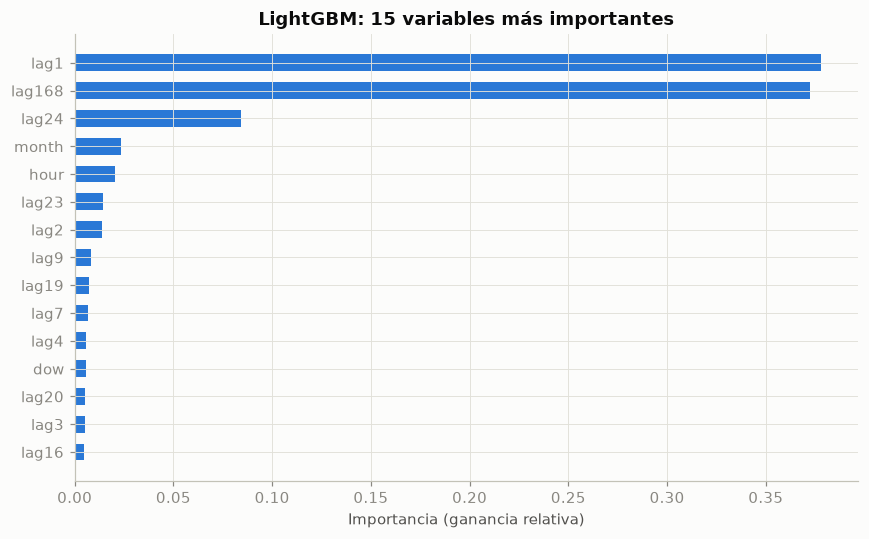

In [30]:
print("== LightGBM")
lgbm = BL.LightGBMGlobal(max_rows=300_000 if QUICK else 2_000_000, num_boost_round=50 if QUICK else 2000)
preds, info = BT.backtest(lgbm, panel, split="test")
n_nodes = len(lgbm.booster.trees_to_dataframe())
evaluate_and_save("LightGBM", preds, info, {"family": "Árboles", "L": 168, "strategy": "recursiva", "uses_cov": True,
                                            "params_total": n_nodes, "params_trainable": n_nodes,
                                            "train_time_s": lgbm.train_time, "epochs": lgbm.booster.best_iteration,
                                            "hardware": HW_CPU})
print(f"  árboles: {lgbm.booster.num_trees()} (mejor iteración {lgbm.booster.best_iteration}), nodos: {n_nodes:,}")
imp = pd.Series(lgbm.booster.feature_importance("gain"), index=lgbm.booster.feature_name()).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index[-15:], imp.values[-15:] / imp.sum(), color=PALETTE[0], height=0.6)
ax.set_xlabel("Importancia (ganancia relativa)"); ax.set_title("LightGBM: 15 variables más importantes")
plt.tight_layout(); savefig(fig, "5_lightgbm_importancia"); plt.show()

### MLP y lineales: MLP multi-salida, DLinear y NLinear

- **MLP:** aplana la ventana `(L × 8)` junto con el calendario futuro `(24 × 7)` y devuelve los 24 pasos con una capa densa final (2 capas ocultas de 512, ReLU, dropout 0.1).
- **DLinear:** separa la tendencia (media móvil de 25 h) del resto y aplica una capa lineal `L → 24` a cada parte. Usa solo la serie objetivo, sin covariables.
- **NLinear:** resta el último valor de la ventana, aplica una capa lineal `L → 24` y lo vuelve a sumar.

In [31]:
_ = run_torch(TR.TorchForecaster("MLP", partial(MD.build_mlp, hidden=512, n_layers=2, dropout=0.1),
                             family="MLP y lineales", strategy="multi-salida", uses_cov=True, **TRAIN_KW), {})
_ = run_torch(TR.TorchForecaster("DLinear", partial(MD.build_dlinear, kernel=25),
                             family="MLP y lineales", strategy="multi-salida", uses_cov=False, **TRAIN_KW), {})
_ = run_torch(TR.TorchForecaster("NLinear", MD.build_nlinear,
                             family="MLP y lineales", strategy="multi-salida", uses_cov=False, **TRAIN_KW), {})

== MLP


  ep 01 | train 0.3195 | val 0.2752 | MAE 54.72 kWh | MASE 0.938 | 2.3s


  ep 02 | train 0.2782 | val 0.2699 | MAE 54.80 kWh | MASE 0.921 | 1.9s


  ep 03 | train 0.2718 | val 0.2691 | MAE 55.44 kWh | MASE 0.924 | 1.9s


  ep 04 | train 0.2694 | val 0.2640 | MAE 54.64 kWh | MASE 0.906 | 2.1s


...

  ep 13 | train 0.2615 | val 0.2692 | MAE 52.47 kWh | MASE 0.884 | 2.0s


  ep 14 | train 0.2599 | val 0.2697 | MAE 52.34 kWh | MASE 0.888 | 2.0s


  ep 15 | train 0.2625 | val 0.2722 | MAE 54.08 kWh | MASE 0.901 | 2.1s


[NLinear] test: 92 orígenes | fit 31.9s | inferencia 0.3s


  -> MAE 45.44 kWh | RMSE 405.37 | WAPE 0.077 | MASE 0.882 | MASE 22-28 dic 1.829


### Recurrentes: LSTM multi-salida

LSTM de 2 capas (hidden 128, dropout 0.1). El último estado oculto se concatena con el calendario de las 24 horas futuras y una capa densa devuelve los 24 pasos.

In [32]:
RNN_KW = dict(hidden=128, n_layers=2, dropout=0.1, cell="lstm")
_ = run_torch(TR.TorchForecaster("LSTM", partial(MD.build_rnn_mo, **RNN_KW),
                             family="Recurrentes", strategy="multi-salida", uses_cov=True, **TRAIN_KW), {})

== LSTM


  ep 01 | train 0.3938 | val 0.3347 | MAE 69.45 kWh | MASE 1.154 | 24.1s


  ep 02 | train 0.3125 | val 0.3174 | MAE 67.26 kWh | MASE 1.098 | 23.8s


  ep 03 | train 0.3003 | val 0.3044 | MAE 62.59 kWh | MASE 1.042 | 23.9s


  ep 04 | train 0.2941 | val 0.3072 | MAE 60.91 kWh | MASE 1.039 | 23.8s


...

  ep 28 | train 0.2505 | val 0.2650 | MAE 51.96 kWh | MASE 0.899 | 38.2s


  ep 29 | train 0.2499 | val 0.2636 | MAE 50.63 kWh | MASE 0.892 | 35.8s


  ep 30 | train 0.2498 | val 0.2660 | MAE 52.06 kWh | MASE 0.903 | 37.6s


[LSTM] test: 92 orígenes | fit 914.0s | inferencia 2.6s


  -> MAE 44.64 kWh | RMSE 369.05 | WAPE 0.075 | MASE 0.871 | MASE 22-28 dic 1.566


### Encoder–decoder: seq2seq con covariables de calendario en el decoder

- **Encoder:** una LSTM que resume las L horas en su estado `(h, c)`.
- **Decoder:** otra LSTM, inicializada con ese estado, que recorre las 24 horas futuras recibiendo **su calendario** (hora, día, mes, feriado). Una capa lineal convierte cada salida del decoder en el pronóstico de esa hora.

El decoder no se alimenta con sus propias predicciones (`feed_prev=False`), así que no hay exposición a errores acumulados. La clase también admite `feed_prev=True` con teacher forcing.

In [33]:
_ = run_torch(TR.TorchForecaster("Seq2Seq", partial(MD.build_seq2seq, **RNN_KW, feed_prev=False),
                             family="Encoder–decoder", strategy="encoder–decoder", uses_cov=True, **TRAIN_KW), {})

== Seq2Seq


  ep 01 | train 0.4337 | val 0.3558 | MAE 74.78 kWh | MASE 1.224 | 38.9s


  ep 02 | train 0.3256 | val 0.3251 | MAE 65.83 kWh | MASE 1.108 | 41.1s


  ep 03 | train 0.3083 | val 0.3147 | MAE 63.05 kWh | MASE 1.072 | 39.9s


  ep 04 | train 0.3008 | val 0.3143 | MAE 63.20 kWh | MASE 1.070 | 43.3s


...

  ep 28 | train 0.2451 | val 0.2637 | MAE 52.04 kWh | MASE 0.888 | 39.7s


  ep 29 | train 0.2447 | val 0.2605 | MAE 50.21 kWh | MASE 0.878 | 37.1s


  ep 30 | train 0.2436 | val 0.2573 | MAE 48.88 kWh | MASE 0.864 | 39.7s


[Seq2Seq] test: 92 orígenes | fit 1223.0s | inferencia 3.1s


  -> MAE 43.14 kWh | RMSE 363.98 | WAPE 0.073 | MASE 0.831 | MASE 22-28 dic 1.414


### 5.1 Estrategias multi-paso con la LSTM 

Comparamos las tres estrategias con la misma LSTM (2 capas, hidden 128, mismos datos y la misma normalización):

| Estrategia | Entrenamiento | Inferencia |
|---|---|---|
| **Autorregresiva** | Predice t+1 con *teacher forcing*: la entrada incluye los valores reales del horizonte desplazados un paso | Predice un paso, realimenta su predicción y repite 24 veces |
| **Multi-salida** | Una capa densa devuelve los 24 pasos (la LSTM multi-salida de arriba) | Igual |
| **Encoder–decoder** | Encoder + decoder con calendario futuro (el seq2seq de arriba) | Igual |

In [34]:
_ = run_torch(TR.TorchForecaster("LSTM_AR", partial(MD.build_rnn_ar, **RNN_KW),
                             family="Recurrentes", strategy="autorregresiva", uses_cov=True, **TRAIN_KW), {})

== LSTM_AR


  ep 01 | train 0.3084 | val 0.3818 | MAE 79.35 kWh | MASE 1.306 | 47.0s


  ep 02 | train 0.2298 | val 0.3535 | MAE 80.82 kWh | MASE 1.225 | 43.4s


  ep 03 | train 0.2189 | val 0.3235 | MAE 61.91 kWh | MASE 1.082 | 48.7s


  ep 04 | train 0.2125 | val 0.3127 | MAE 61.73 kWh | MASE 1.041 | 42.2s


...

  ep 28 | train 0.1743 | val 0.2626 | MAE 49.93 kWh | MASE 0.870 | 46.5s


  ep 29 | train 0.1739 | val 0.2632 | MAE 49.34 kWh | MASE 0.874 | 42.8s


  ep 30 | train 0.1733 | val 0.2646 | MAE 53.09 kWh | MASE 0.894 | 43.5s


[LSTM_AR] test: 92 orígenes | fit 1292.2s | inferencia 5.6s


  -> MAE 43.30 kWh | RMSE 370.84 | WAPE 0.073 | MASE 0.832 | MASE 22-28 dic 1.394


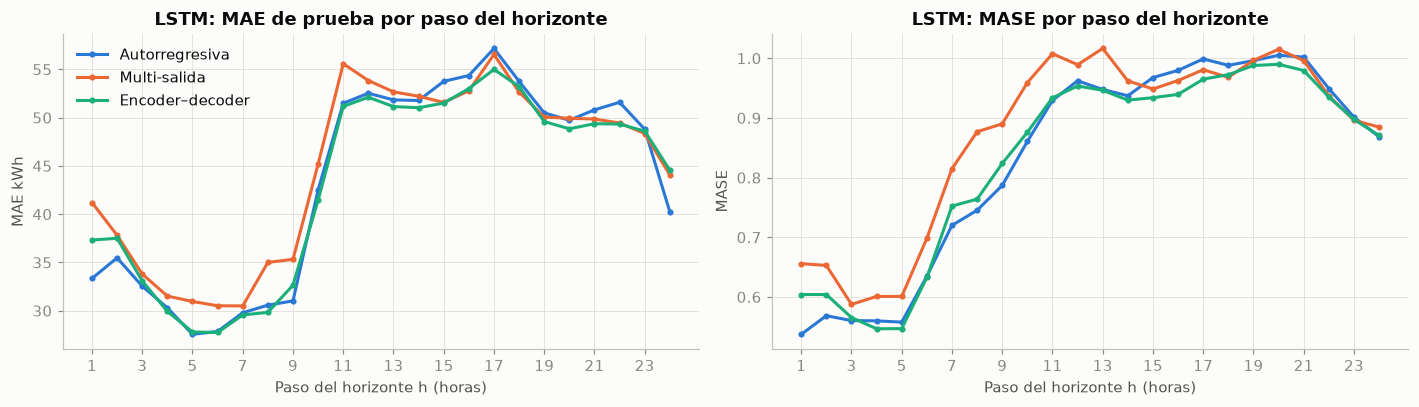

h,h=1,h=6,h=12,h=18,h=24
Autorregresiva,33.349998,27.85,52.529999,53.759998,40.240002
Multi-salida,41.209999,30.51,53.840000,52.650002,44.070000
Encoder–decoder,37.320000,27.75,52.110001,53.220001,44.549999


,params_total,epochs_run,train_time_s,val_MAE,val_MASE
Autorregresiva,202881,30,1291.779871,49.932404,0.87011
Multi-salida,209880,30,913.970365,50.63216,0.891559
Encoder–decoder,405121,30,1222.925711,48.884315,0.863606


In [35]:
strat = {"LSTM_AR": "Autorregresiva", "LSTM": "Multi-salida", "Seq2Seq": "Encoder–decoder"}
by_h_strat = {k: ME.by(ALL_PREDS[k], stats, "h") for k in strat}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, (name, label) in enumerate(strat.items()):
    t = by_h_strat[name]
    for ax, col in zip(axes, ["MAE", "MASE"]):
        ax.plot(t["h"], t[col], color=PALETTE[k], marker="o", ms=3, label=label)
for ax, col, unit in zip(axes, ["MAE", "MASE"], ["kWh", ""]):
    ax.set_xlabel("Paso del horizonte h (horas)"); ax.set_ylabel(f"{col} {unit}".strip())
    ax.set_xticks(range(1, 25, 2))
axes[0].set_title("LSTM: MAE de prueba por paso del horizonte"); axes[1].set_title("LSTM: MASE por paso del horizonte")
axes[0].legend()
plt.tight_layout(); savefig(fig, "5_1_estrategias_por_paso"); plt.show()

hist_cmp = pd.DataFrame({label: NETS[name].summary() for name, label in strat.items()}).T
display(pd.DataFrame({label: by_h_strat[name].set_index("h")["MAE"].iloc[[0, 5, 11, 17, 23]]
                      for name, label in strat.items()}).T.round(2).rename(columns=lambda h: f"h={h}"))
display(hist_cmp[["params_total", "epochs_run", "train_time_s", "val_MAE", "val_MASE"]])

**Comparación de estrategias (misma LSTM, prueba).**

| | Autorregresiva | Multi-salida | Encoder–decoder |
|---|---|---|---|
| MASE prueba | 0.832 | 0.871 | **0.831** |
| MASE h=1 | **0.537** | 0.656 | 0.604 |
| MASE h=12 | 0.962 | 0.989 | **0.954** |
| Parámetros | 203k | 210k | 405k |
| Entrenamiento | 1,292 s | **914 s** | 1,223 s |
| Inferencia (92 orígenes) | 5.6 s | **2.6 s** | 3.1 s |

- **Cuidado al leer las curvas: aquí h coincide con la hora del día**, porque todos los orígenes son a las 00:00. El salto en h≈10–11 es la subida de consumo de la mañana, no una degradación por alejarse del origen. Por eso el error vuelve a bajar en h=24 (23:00).
- **La autorregresiva gana en los primeros pasos.** Predice un paso a la vez a partir del último valor real.
- **No aparece la acumulación de errores esperada.** De h=12 a h=24 la autorregresiva queda a la par del encoder–decoder.
  - En entrenamiento sí se ve el costo del *teacher forcing*: su pérdida de entrenamiento (0.17) queda muy por debajo de la de validación (0.26). En las demás estrategias la diferencia es mínima.
  - También es la más lenta: 24 pasos secuenciales en inferencia.
- **La multi-salida es la peor**, sobre todo en la madrugada y la rampa de la mañana (h 1–10). Su capa densa solo ve el último estado oculto.
- **El encoder–decoder es el más equilibrado.** En cada paso combina el estado del encoder con el calendario de esa hora.
- **Ninguna de las tres activó el early stopping en 30 epochs.** La pérdida de validación seguía bajando, así que hay margen con más epochs. Esto queda como pendiente para la búsqueda de hiperparámetros (5.2).

## 6. Comparación de resultados (Parte 1)

### 6.1 Tabla comparativa ordenada por MASE

In [36]:
res = pd.DataFrame(RESULTS).sort_values("MASE").reset_index(drop=True)
res.to_csv(C.RESULTS_DIR / "test_metrics_parte1.csv", index=False)
cols = ["model", "family", "L", "strategy", "uses_cov", "params_total", "params_trainable", "train_time_s",
        "infer_time_s", "hardware", "MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_xmas"]
display(res[cols].style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "WAPE": "{:.3f}", "MAPE": "{:.3f}",
                                "MASE": "{:.3f}", "MASE_xmas": "{:.3f}", "train_time_s": "{:.0f}",
                                "infer_time_s": "{:.1f}", "params_total": "{:,.0f}", "params_trainable": "{:,.0f}"}))

,model,family,L,strategy,uses_cov,params_total,params_trainable,train_time_s,infer_time_s,hardware,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas
0,Seq2Seq,Encoder–decoder,168,encoder–decoder,True,"405,121","405,121",1223,3.1,NVIDIA GeForce RTX 4050 Laptop GPU,43.14,363.98,0.073,0.096,0.831,1.414
1,LSTM_AR,Recurrentes,168,autorregresiva,True,"202,881","202,881",1292,5.6,NVIDIA GeForce RTX 4050 Laptop GPU,43.30,370.84,0.073,0.101,0.832,1.394
2,MLP,MLP y lineales,168,multi-salida,True,"1,049,624","1,049,624",46,0.3,NVIDIA GeForce RTX 4050 Laptop GPU,43.35,372.21,0.073,0.103,0.836,1.449
3,LSTM,Recurrentes,168,multi-salida,True,"209,880","209,880",914,2.6,NVIDIA GeForce RTX 4050 Laptop GPU,44.64,369.05,0.075,0.103,0.871,1.566
4,LightGBM,Árboles,168,recursiva,True,"201,641","201,641",47,16.7,CPU (16 hilos),43.85,371.58,0.074,0.114,0.880,1.717
5,NLinear,MLP y lineales,168,multi-salida,False,"4,056","4,056",32,0.3,NVIDIA GeForce RTX 4050 Laptop GPU,45.44,405.37,0.077,0.121,0.882,1.829
6,DLinear,MLP y lineales,168,multi-salida,False,"8,112","8,112",22,0.3,NVIDIA GeForce RTX 4050 Laptop GPU,45.52,403.77,0.077,0.122,0.885,1.837
7,MSTL,Baseline,504,local (reajuste por origen),False,0,0,0,553.8,CPU (16 hilos),48.63,427.31,0.082,0.120,0.926,1.964
8,SeasonalNaive24,Baseline,24,local (reajuste por origen),False,0,0,0,0.3,CPU (16 hilos),50.01,394.89,0.084,0.141,1.044,2.235
9,SeasonalNaive168,Baseline,168,local (reajuste por origen),False,0,0,0,0.4,CPU (16 hilos),56.63,626.53,0.096,0.122,1.074,1.623


**Lectura de la tabla.**

- **Los tres primeros están prácticamente empatados:** Seq2Seq (0.831), LSTM_AR (0.832) y MLP (0.836).
  - El **MLP entrena en 46 s**, 26 veces menos que Seq2Seq (1,223 s), e infiere en 0.3 s.
  - Es la mejor relación costo/beneficio de la Parte 1.
- **Todos los modelos aprendidos superan al SeasonalNaive24** (MASE 1.044) entre 15% y 20%.
  - Seq2Seq le gana en el **95%** de los clientes y a LightGBM en el 78%.
- **DLinear y NLinear ya llegan a 0.88** con 4–8 mil parámetros y sin covariables. La mayor parte de la señal está en el patrón diario/semanal de los rezagos.
  - Las covariables de calendario pesan sobre todo en feriados: en la semana de Navidad, MASE 1.83 contra 1.41–1.45 de los modelos con calendario.
- **LightGBM (0.880) queda a la altura de la LSTM multi-salida.** Tiene el segundo mejor MAE en kWh, porque su objetivo escalado por la media favorece a los clientes grandes. En MASE queda más atrás.
- **MSTL (0.926) es el mejor baseline estadístico, pero el más caro:** 554 s de inferencia, porque reajusta 315 × 92 modelos.
- **Naive (3.99) solo sirve de referencia:** repetir el último valor ignora el ciclo diario por completo.

### 6.2 Error por paso del horizonte, por hora del día y por cliente

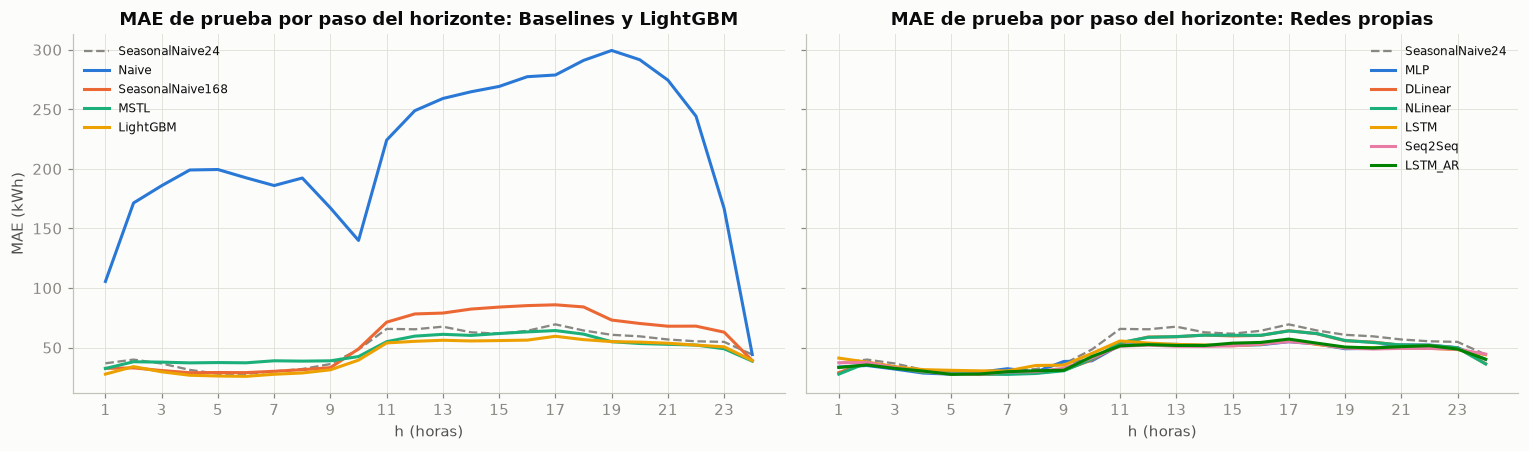

Error por hora del día (MAE, kWh), modelos seleccionados:


hour,0,3,6,9,12,15,18,21
model,,,,,,,,
SeasonalNaive24,36.840000,31.309999,30.059999,48.470001,67.580002,64.129997,60.750000,55.310001
LightGBM,27.770000,26.799999,27.629999,39.520000,56.180000,56.290001,55.029999,52.119999
MLP,33.720001,28.650000,32.299999,38.910000,52.759998,52.400002,49.070000,52.169998
DLinear,29.000000,29.330000,28.219999,39.639999,59.080002,60.240002,55.740002,51.880001
LSTM,41.209999,31.520000,30.500000,45.180000,52.669998,52.779999,50.049999,49.439999
Seq2Seq,37.320000,29.940001,29.559999,41.450001,51.150002,53.009998,49.590000,49.330002


In [37]:
by_h = pd.concat([ME.by(p, stats, "h").assign(model=k) for k, p in ALL_PREDS.items()])
by_hour = pd.concat([ME.by(p, stats, "hour").assign(model=k) for k, p in ALL_PREDS.items()])
by_client = pd.concat([ME.by(p, stats, "unique_id").assign(model=k) for k, p in ALL_PREDS.items()])
by_h.to_csv(C.RESULTS_DIR / "test_by_horizon.csv", index=False)
by_hour.to_csv(C.RESULTS_DIR / "test_by_hour.csv", index=False)
by_client.to_csv(C.RESULTS_DIR / "test_by_client.csv", index=False)

# Dos paneles para no pasar de 8 colores por gráfica; el seasonal naive 24 h va en gris como referencia.
groups = [("Baselines y LightGBM", ["Naive", "SeasonalNaive168", "MSTL", "LightGBM"]),
          ("Redes propias", ["MLP", "DLinear", "NLinear", "LSTM", "Seq2Seq", "LSTM_AR"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (title, names) in zip(axes, groups):
    ref = by_h[by_h.model == "SeasonalNaive24"]
    ax.plot(ref["h"], ref["MAE"], color=GRAY, ls="--", lw=1.5, label="SeasonalNaive24")
    for k, n in enumerate([n for n in names if n in ALL_PREDS]):
        t = by_h[by_h.model == n]
        ax.plot(t["h"], t["MAE"], color=PALETTE[k], label=n)
    ax.set_title(f"MAE de prueba por paso del horizonte: {title}"); ax.set_xlabel("h (horas)")
    ax.set_xticks(range(1, 25, 2)); ax.legend(fontsize=8)
axes[0].set_ylabel("MAE (kWh)")
plt.tight_layout(); savefig(fig, "6_2_mae_por_paso"); plt.show()

# Como todos los orígenes son a las 00:00, el paso h corresponde siempre a la hora h-1.
assert np.allclose(by_h[by_h.model == "LSTM"]["MAE"].values, by_hour[by_hour.model == "LSTM"]["MAE"].values)
print("Error por hora del día (MAE, kWh), modelos seleccionados:")
display(by_hour.pivot(index="hour", columns="model", values="MAE")[
    [n for n in ["SeasonalNaive24", "LightGBM", "MLP", "DLinear", "LSTM", "Seq2Seq"] if n in ALL_PREDS]]
    .iloc[::3].round(2).T)

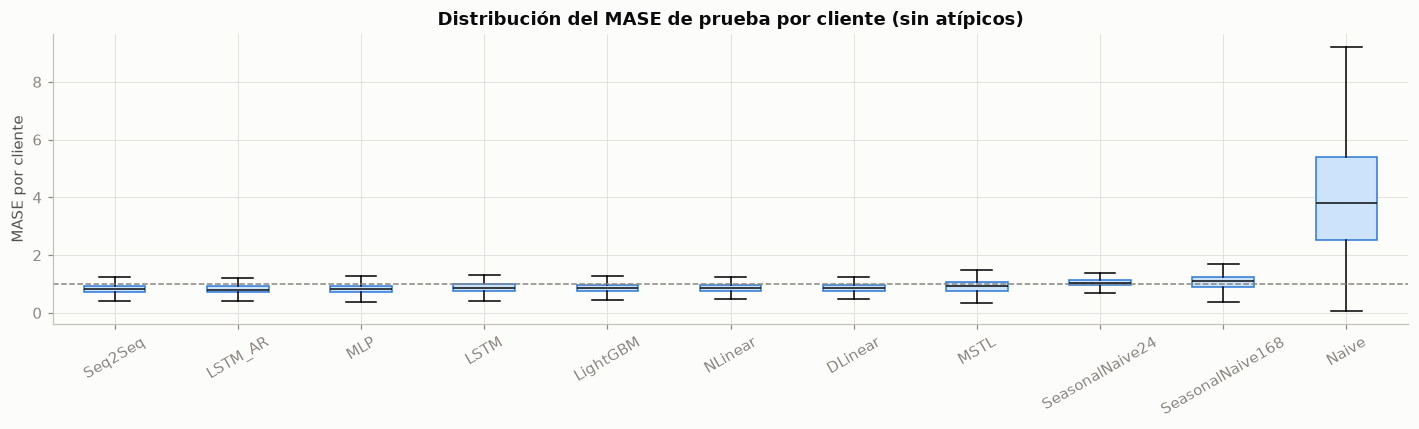

In [38]:
# MASE por cliente: distribución por modelo
order = res["model"].tolist()
fig, ax = plt.subplots(figsize=(13, 4))
data_ = [by_client[by_client.model == n]["MASE"].values for n in order]
bp = ax.boxplot(data_, tick_labels=order, showfliers=False, patch_artist=True, widths=0.5,
                medianprops={"color": "#0b0b0b"})
for b in bp["boxes"]:
    b.set_facecolor("#cde2fb"); b.set_edgecolor(PALETTE[0])
ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.set_ylabel("MASE por cliente"); ax.set_title("Distribución del MASE de prueba por cliente (sin atípicos)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig(fig, "6_2_mase_por_cliente"); plt.show()

### 6.3 MAPE y clientes de consumo cercano a cero

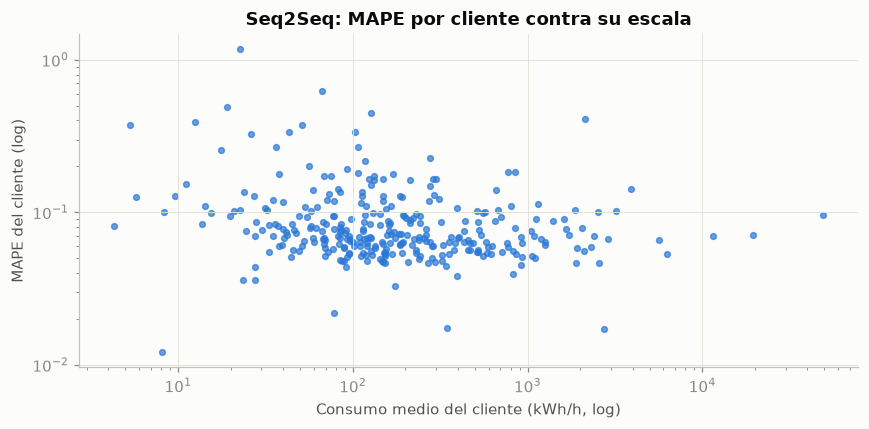

,unique_id,mean,frac_y<1kWh,MAE,MAPE,MASE
83,MT_093,22.681000,0.000,19.459999,1.171,1.193
111,MT_140,66.509003,0.000,42.914001,0.625,1.434
293,MT_348,19.041000,0.439,7.197000,0.488,0.551
81,MT_090,127.202003,0.000,22.996000,0.447,0.414
291,MT_345,2119.990967,0.000,139.104004,0.412,1.158
311,MT_366,12.500000,0.001,3.617000,0.391,0.461
0,MT_001,5.300000,0.198,0.536000,0.373,0.265
127,MT_159,51.366001,0.000,12.253000,0.372,0.511


MAPE del panel (Seq2Seq): 9.6% | mediana del MAPE por cliente: 7.1% | WAPE: 7.3%


In [39]:
best = res.loc[0, "model"]
pc = by_client[by_client.model == best].merge(stats, on="unique_id")
p = ALL_PREDS[best]
near_zero = (p.groupby("unique_id")["y"].apply(lambda s: (s.abs() < 1).mean())).rename("frac_y<1kWh")
pc = pc.merge(near_zero, on="unique_id")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(pc["mean"], pc["MAPE"], s=14, color=PALETTE[0], alpha=0.7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Consumo medio del cliente (kWh/h, log)"); ax.set_ylabel("MAPE del cliente (log)")
ax.set_title(f"{best}: MAPE por cliente contra su escala")
plt.tight_layout(); savefig(fig, "6_3_mape_vs_escala"); plt.show()
display(pc.sort_values("MAPE", ascending=False)[["unique_id", "mean", "frac_y<1kWh", "MAE", "MAPE", "MASE"]].head(8).round(3))
print(f"MAPE del panel ({best}): {res.loc[0, 'MAPE']:.1%} | mediana del MAPE por cliente: {pc['MAPE'].median():.1%} | "
      f"WAPE: {res.loc[0, 'WAPE']:.1%}")

**MAPE.**

- **Las medidas agregadas no coinciden:** el MAPE del panel es **9.6%**, la mediana por cliente 7.1% y el WAPE 7.3%.
- **Unos pocos clientes inflan el promedio.** 17 clientes superan el 20% de MAPE.
- **Dos patrones distintos:**
  - **Denominadores cerca de cero.** MT_348 tiene el **44% de sus horas por debajo de 1 kWh**. Su MAPE es 49%, aunque su MASE (0.55) dice que el pronóstico es bueno. El MAPE castiga un error de 0.5 kWh como si fuera enorme.
  - **Cambios de régimen.** MT_093 (MAPE 117%) y MT_140 (62%) no tienen consumos cercanos a cero, pero su MASE > 1.1 indica que el modelo realmente falla.
- **La relación con la escala es débil** (Spearman −0.23): los clientes pequeños tienden a tener MAPE más alto, pero no es determinante.

Conclusión: el MAPE se reporta (excluyendo filas con y = 0) pero no sirve como métrica principal. Exagera los errores pequeños en series casi nulas. Para comparar modelos usamos MASE y WAPE.

### 6.4 Semana del 22 al 28 de diciembre

,model,MASE,MASE_xmas,cambio
0,Seq2Seq,0.831,1.414,+70%
1,LSTM_AR,0.832,1.394,+68%
2,MLP,0.836,1.449,+73%
3,LSTM,0.871,1.566,+80%
4,LightGBM,0.880,1.717,+95%
5,NLinear,0.882,1.829,+107%
6,DLinear,0.885,1.837,+108%
7,MSTL,0.926,1.964,+112%
8,SeasonalNaive24,1.044,2.235,+114%
9,SeasonalNaive168,1.074,1.623,+51%


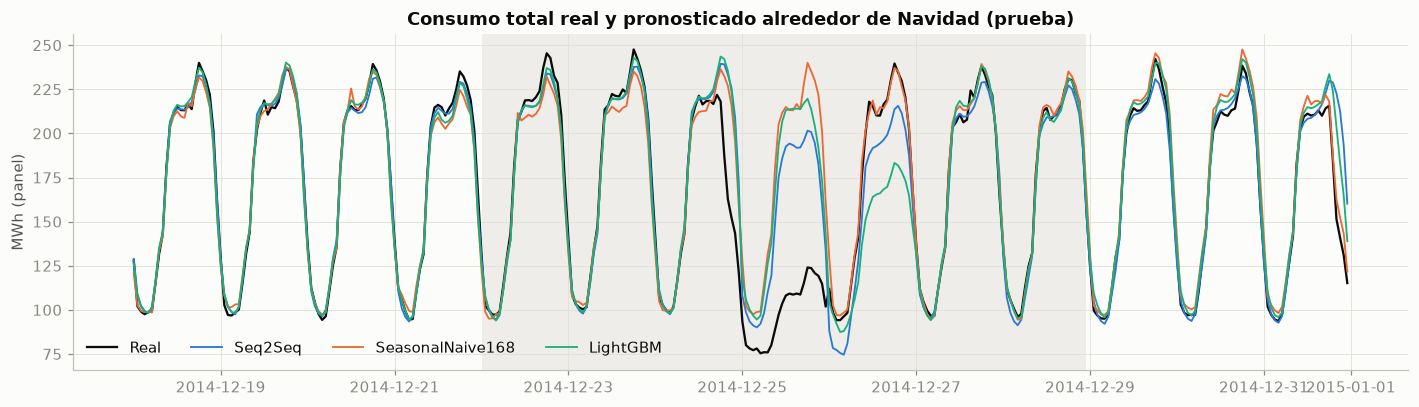

In [40]:
xm = res[["model", "MASE", "MASE_xmas"]].copy()
xm["cambio"] = xm["MASE_xmas"] / xm["MASE"] - 1
display(xm.style.format({"MASE": "{:.3f}", "MASE_xmas": "{:.3f}", "cambio": "{:+.0%}"}))

fig, ax = plt.subplots(figsize=(13, 3.8))
sl = slice("2014-12-18", "2014-12-31 23:00")
tot = lambda p: p.groupby("ds")[["y", "y_hat"]].sum().loc[sl] / 1e3
ax.plot(tot(ALL_PREDS[best])["y"], color="#0b0b0b", lw=1.5, label="Real")
shown = [best] + [n for n in ["SeasonalNaive168", "LightGBM"] if n in ALL_PREDS and n != best]
for k, n in enumerate(shown):
    ax.plot(tot(ALL_PREDS[n])["y_hat"], color=PALETTE[k], lw=1.2, label=n)
ax.axvspan(C.XMAS_START, C.XMAS_END, color="#e1e0d9", alpha=0.5, lw=0)
ax.set_ylabel("MWh (panel)"); ax.set_title("Consumo total real y pronosticado alrededor de Navidad (prueba)")
ax.legend(ncol=4)
plt.tight_layout(); savefig(fig, "6_4_navidad_pronostico"); plt.show()

**Semana del 22 al 28 de diciembre de 2014.**

- **Todos los modelos empeoran en esta semana.** Su MASE sube entre 68% y 114%.
  - En términos absolutos los mejores siguen siendo **LSTM_AR (1.394) y Seq2Seq (1.414)**.
  - SN168 "solo" empeora 51% porque ya partía de un error alto.
- **Casi todo el error se concentra en el 25 de diciembre (jueves).**
  - El consumo real del panel cae a ~75–125 MWh por hora, contra ~220 de un día normal.
  - Seq2Seq usa la variable `holiday` y baja su pronóstico a un pico de ~200. Va en la dirección correcta, pero se queda corto.
  - SeasonalNaive168 y LightGBM pronostican un día casi normal (picos de 220–240).
- **El 26 de diciembre (viernes) el consumo vuelve a la normalidad, pero varios modelos se equivocan.**
  - **LightGBM es recursivo:** su rezago de 24 h es Navidad, así que subestima el pico (~183 contra ~240 real).
  - Seq2Seq también arranca la madrugada demasiado bajo.
- **Causa de fondo:** en entrenamiento solo hay dos Navidades. Un evento tan raro y tan fuerte no se aprende bien con una sola variable binaria.
- **Ideas para la Parte 2:**
  - variables como "día posterior a un feriado" o "días hasta Navidad";
  - más peso a los feriados en la pérdida;
  - intervalos probabilísticos que se ensanchen en estas fechas.

### 6.5 Exportación de pronósticos de prueba

In [41]:
allp = pd.concat([p[["unique_id", "ds", "model", "y_hat"]] for p in ALL_PREDS.values()], ignore_index=True)
allp = allp.rename(columns={"model": "modelo"})
allp.to_parquet(C.PREDS_DIR / "test_predictions_parte1.parquet", index=False)
print(f"{len(allp):,} filas | modelos: {sorted(allp['modelo'].unique())}")
display(allp.head())

7,650,720 filas | modelos: ['DLinear', 'LSTM', 'LSTM_AR', 'LightGBM', 'MLP', 'MSTL', 'NLinear', 'Naive', 'SeasonalNaive168', 'SeasonalNaive24', 'Seq2Seq']


,unique_id,ds,modelo,y_hat
0,MT_001,2014-10-01 00:00:00,Naive,2.220812
1,MT_001,2014-10-01 01:00:00,Naive,2.220812
2,MT_001,2014-10-01 02:00:00,Naive,2.220812
3,MT_001,2014-10-01 03:00:00,Naive,2.220812
4,MT_001,2014-10-01 04:00:00,Naive,2.220812


## Notas para la Parte 2

```python
from lab9 import config as C, data as D, backtest as BT, metrics as ME, models as MD, training as TR
panel = D.load_panel()                          # mismo panel de 315 clientes
stats = pd.read_csv(C.STATS_PATH)               # escala del MASE (solo entrenamiento)

# 5.2: iteraciones; validación únicamente. Cada fit registra config, curvas, tiempos y memoria GPU.
m = TR.TorchForecaster("LSTM_L336", partial(MD.build_rnn_mo, hidden=128, n_layers=2),
                       L=336, history_months=12, norm="window", lr=1e-3, batch_size=512)
preds_val, info = BT.backtest(m, panel, split="val")     # entrena y mide inferencia en los 92 orígenes de validación
TR.save_run(m, info)                                     # -> results/runs.csv + results/history/<run>.csv

# Reentrenamiento mensual con ventana expandible (3 orígenes: 1 oct, 1 nov, 1 dic)
preds, info = BT.backtest(m, panel, split="test", refit_every="MS")

# Métricas de cualquier modelo (NeuralForecast, Chronos...) con columnas unique_id, ds, y, y_hat [, q0.1, q0.9]
ME.evaluate(df, stats, "PatchTST"); ME.by(df, stats, "h")
```

- Los pronósticos de NeuralForecast y Chronos deben tener las mismas columnas que `preds/<modelo>.parquet` para unirse a `test_predictions_parte1.parquet`.
- `history_months` en `TorchForecaster` y `LightGBMGlobal` controla la historia de entrenamiento (3, 12, 30 meses).
- La semilla se fija con `seed=` en `TorchForecaster`, para las 3 repeticiones del mejor modelo.